#**Project Name** - Portuguese Bank Marketing Project

##### **Project Type**    - Classification (Supervised)
##### **Contribution**    - Individual

# **Project Summary**

A Portuguese bank sells term deposits through direct phone calls, but only 11.3% of calls succeed. This project analyses 41,188 calls from the 2008 to 2010 campaigns (41,176 after removing 12 duplicates) and builds a classification model that predicts which customers will subscribe, so the marketing team can call the most promising customers first.

**Approach.** The data was cleaned (hidden "unknown" values, the special code pdays = 999, and removal of the call duration, which is only known after the call and would leak the answer). Fourteen charts and four statistical tests (Chi-square, Welch's t-test, Mann-Whitney U) showed that the previous campaign outcome, contact type, the Euribor interest rate and the number of contacts are strongly linked to subscription. After outlier capping, encoding, a log transform and a stratified 80/20 split, features were scaled and the training data was balanced with SMOTE, leaving the test set untouched.

**Modelling.** Five algorithms (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost) were trained and tuned with 3-fold cross-validated grid search, with SMOTE inside the pipeline to avoid leakage. Ten model versions were compared on Precision, Recall, F1 and ROC-AUC, because accuracy is misleading on imbalanced data.

**Result.** The tuned Random Forest was chosen (F1 0.508, ROC-AUC 0.804, recall 0.613, precision 0.433). On the test set it found 569 of the 928 real subscribers, and about 43% of the customers it flagged subscribed, against 11.3% for random calling. Economic indicators account for about 53% of feature importance, followed by contact history, previous outcome and contact type. The model was saved with its scaler as a pickle file.

**Recommendations.** Call customers in model order, start with previous successes, prefer mobile numbers, limit attempts to 3 to 5 per customer, time campaigns around low interest-rate periods, and tailor offers by segment.

**Limitations.** The top models perform similarly, the data covers one period (2008 to 2010), and the results show associations, not causes.

# **GitHub Link -**

https://github.com/padalasaikiran/Portuguese-Bank-Marketing-Project

# **Problem Statement**

A Portuguese bank runs direct phone-call marketing campaigns to sell term deposits to its existing customers. Calling every customer is costly and most calls end in "no" (only about 11% say yes).

**Goal:** Analyse the campaign data (41,188 calls, 20 features) and build a classification model that predicts whether a customer will subscribe to a term deposit, so that:
- The marketing team can focus calls on customers most likely to say yes.
- Calling cost and customer annoyance are reduced.
- The bank understands which factors (age, job, economic conditions, previous campaign outcome, contact type) influence a purchase.

**Tasks:**
1. Complete data analysis report
2. Predictive model for buying likelihood
3. Suggestions to the marketing team

# ***Project Workflow***

This project follows a structured, end-to-end workflow: data understanding, data wrangling, visualization, hypothesis testing, feature engineering, model building, model comparison, and business recommendations.

## Section 1: Data Overview

### Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pickle
import warnings
warnings.filterwarnings("ignore")

In [3]:
from google.colab import data_table
data_table.disable_dataframe_formatter()

### Dataset Loading

In [4]:
# Load Dataset
df = pd.read_csv("bank-additional-full.csv", sep=";")

### Dataset First View

In [5]:
# Dataset First Look
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Dataset Rows & Columns count

In [6]:
# Dataset Rows & Columns count
df.shape

(41188, 21)

### Dataset Information

In [7]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

#### Duplicate Values

In [8]:
# Dataset Duplicate Value Count
df.duplicated().sum()

np.int64(12)

#### Missing Values/Null Values

In [9]:
# Missing Values/Null Values Count
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


#### Hidden Missing Values ("unknown" Category)

In [10]:
# Hidden missing values: 'unknown' counts per column
unknown_counts = (df == 'unknown').sum()
unknown_counts[unknown_counts > 0]

,0
job,330
marital,80
education,1731
default,8597
housing,990
loan,990


#### Target Variable Distribution

In [11]:
# Target variable distribution
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True) * 100)

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


### Key Observations About the Dataset

- The dataset contains **41,188 rows and 21 columns** (20 input features + the target `y`). Each row is one phone call made during the bank's term-deposit marketing campaign.
- There are **10 numeric columns** (5 integer, 5 float) and **11 categorical (object) columns**.
- There are **12 duplicate rows**, which will be removed during data wrangling.
- There are **no null (NaN) values**, but missing information is hidden as the category **"unknown"**: `default` (8,597 – 20.9%), `education` (1,731 – 4.2%), `housing` and `loan` (990 each – 2.4%), `job` (330 – 0.8%) and `marital` (80 – 0.2%). These must be handled explicitly.
- The target variable `y` is **imbalanced**: 88.7% "no" (36,548) vs 11.3% "yes" (4,640). Accuracy alone will be misleading, so Precision, Recall, F1-score and ROC-AUC will be used.
- The column `duration` (call length) is only known *after* the call, so it will be dropped to build a realistic predictive model.
- `pdays = 999` is a special code meaning "not previously contacted", not a real number of days.

## Section 2: Variable Description and Summary

### Dataset Columns

In [12]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

### Statistical Summary of Numeric Columns

In [13]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


### Statistical Summary of Categorical Columns

In [14]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


### Variables Description

**Target Variable**
`y` — Has the client subscribed to a term deposit? (yes/no)

**Client Information** — age, job, marital, education, default (credit in default), housing (housing loan), loan (personal loan)

**Last Contact of Current Campaign** — contact (cellular/telephone), month, day_of_week, duration (call length in seconds), campaign (number of contacts in this campaign)

**Previous Campaign Information** — pdays (days since last contacted; 999 = never), previous (number of earlier contacts), poutcome (outcome of previous campaign)

**Social & Economic Context** — emp.var.rate (employment variation rate), cons.price.idx (consumer price index), cons.conf.idx (consumer confidence index), euribor3m (3-month Euribor interest rate), nr.employed (number of employees)

### Unique Values in Each Variable

In [15]:
# Number of unique values in each column
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")

age: 78
job: 12
marital: 4
education: 8
default: 3
housing: 3
loan: 3
contact: 2
month: 10
day_of_week: 5
duration: 1544
campaign: 42
pdays: 27
previous: 8
poutcome: 3
emp.var.rate: 10
cons.price.idx: 26
cons.conf.idx: 26
euribor3m: 316
nr.employed: 11
y: 2


In [16]:
# Data type summary
print(df.dtypes.value_counts())

object     11
int64       5
float64     5
Name: count, dtype: int64


In [17]:
print(df.describe().round(2).T.to_string())
print("pdays=999 %:", round((df['pdays']==999).mean()*100, 2))
print("previous=0 %:", round((df['previous']==0).mean()*100, 2))

                  count     mean     std      min      25%      50%      75%      max
age             41188.0    40.02   10.42    17.00    32.00    38.00    47.00    98.00
duration        41188.0   258.29  259.28     0.00   102.00   180.00   319.00  4918.00
campaign        41188.0     2.57    2.77     1.00     1.00     2.00     3.00    56.00
pdays           41188.0   962.48  186.91     0.00   999.00   999.00   999.00   999.00
previous        41188.0     0.17    0.49     0.00     0.00     0.00     0.00     7.00
emp.var.rate    41188.0     0.08    1.57    -3.40    -1.80     1.10     1.40     1.40
cons.price.idx  41188.0    93.58    0.58    92.20    93.08    93.75    93.99    94.77
cons.conf.idx   41188.0   -40.50    4.63   -50.80   -42.70   -41.80   -36.40   -26.90
euribor3m       41188.0     3.62    1.73     0.63     1.34     4.86     4.96     5.04
nr.employed     41188.0  5167.04   72.25  4963.60  5099.10  5191.00  5228.10  5228.10
pdays=999 %: 96.32
previous=0 %: 86.34


### Key Observations on Variables

- The dataset has **11 categorical and 10 numeric variables**. Among the categorical ones, `job` has the most categories (12), followed by `education` (8); `default`, `housing` and `loan` each have three (yes / no / unknown).
- `age` ranges from **17 to 98 years** with a mean of about **40** and a median of 38, so the campaign mainly targeted working-age customers. The maximum of 98 is a possible outlier.
- `campaign` (contacts in this campaign) has a maximum of **56** against a median of **2** and a 75th percentile of 3, which indicates strong **outliers**.
- `pdays` has the special code **999** in **96.32%** of rows (customer never contacted before), so it will be converted into a meaningful feature rather than used as a raw number.
- `previous` is **0 for 86.34%** of customers, so most customers had no earlier contact. Its maximum is 7.
- `duration` has a mean of about **258 seconds** but a maximum of **4,918 seconds** (about 82 minutes), which is a heavy outlier. It will also be dropped from the predictive model because it is only known after the call.
- The economic indicators (`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `nr.employed`) take only a few distinct values because they are quarterly or monthly figures repeated across many calls. `euribor3m` is a daily indicator ranging from 0.63 to 5.04.
- The numeric variables are on very different scales (for example `nr.employed` is around 5,000 while `previous` is around 0.2), so **scaling** will be needed for distance- and gradient-based models.

## Section 3: Data Wrangling

### Removing Duplicate Values

In [18]:
print("Duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows after:", df.duplicated().sum())
print("New shape:", df.shape)

Duplicate rows before: 12
Duplicate rows after: 0
New shape: (41176, 21)


### Visualising Hidden Missing Values ("unknown" Category)

default      20.88
education     4.20
housing       2.40
loan          2.40
job           0.80
marital       0.19
dtype: float64


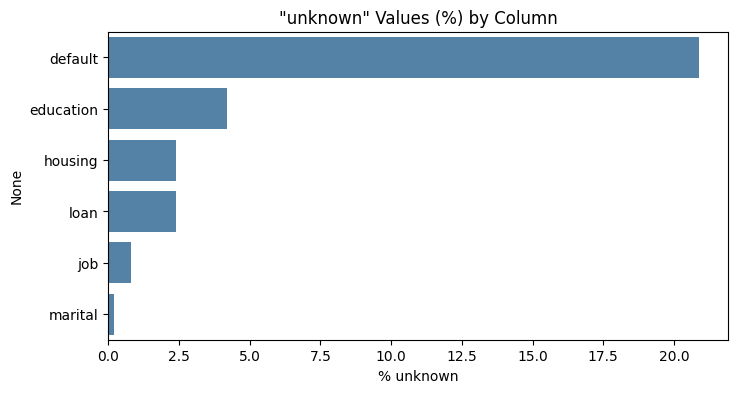

In [19]:
unknown_pct = (df == 'unknown').sum() / len(df) * 100
unknown_pct = unknown_pct[unknown_pct > 0].sort_values(ascending=False)
print(unknown_pct.round(2))

plt.figure(figsize=(8, 4))
sns.barplot(x=unknown_pct.values, y=unknown_pct.index, color="steelblue")
plt.title('"unknown" Values (%) by Column')
plt.xlabel("% unknown")
plt.show()

### Handling "unknown" Values

In [20]:
# 'default' keeps "unknown" as its own category (20.9% is too large to impute)
# All other columns: replace "unknown" with the most frequent value (mode)
mode_cols = ['job', 'marital', 'education', 'housing', 'loan']
for col in mode_cols:
    mode_val = df.loc[df[col] != 'unknown', col].mode()[0]
    df[col] = df[col].replace('unknown', mode_val)
    print(f"{col}: filled with '{mode_val}'")

# Remaining unknown values
remaining = (df == 'unknown').sum()
remaining[remaining > 0]

job: filled with 'admin.'
marital: filled with 'married'
education: filled with 'university.degree'
housing: filled with 'yes'
loan: filled with 'no'


,0
default,8596


### Handling the pdays = 999 Code

In [21]:
# 999 means "not previously contacted" -> create a clear binary flag
df['previously_contacted'] = (df['pdays'] != 999).astype(int)
# Replace the 999 code with 0 so it does not distort the numeric scale
df['pdays'] = df['pdays'].replace(999, 0)

print(df['previously_contacted'].value_counts())

previously_contacted
0    39661
1     1515
Name: count, dtype: int64


### Dropping the duration Column

In [22]:
# duration is only known AFTER the call, so it would cause data leakage
df = df.drop('duration', axis=1)
print("Final shape:", df.shape)

Final shape: (41176, 21)


#### What data wrangling techniques have you used and why?

Four techniques were used, matched to the nature of each problem:
1. **Duplicate removal** – 12 exact duplicate rows were dropped, since repeated records would give some calls extra weight during training and inflate evaluation scores.
2. **Handling "unknown" values** – the dataset has no NaN values, but missing information is stored as the text "unknown". For `job`, `marital`, `education`, `housing` and `loan` (0.2%–4.2% unknown) the **mode** was used, as the share is small and removing rows would waste data. For `default` (20.9% unknown) the value was **kept as a separate category**, because imputing a fifth of the column would invent information, and "unknown" credit status may itself be informative.
3. **Treating pdays = 999 as a special code** – 999 does not mean 999 days but "never contacted before". A binary feature `previously_contacted` was created and 999 was replaced with 0, so the numeric column no longer misleads the models.
4. **Dropping `duration`** – call length is only known after the call ends, so it cannot be used to decide whom to call. Keeping it would cause data leakage and give an unrealistically high model score.

## Section 4: Data Visualization and Storytelling

#### Countplot
#### Chart - 1 : Distribution of the Target Variable

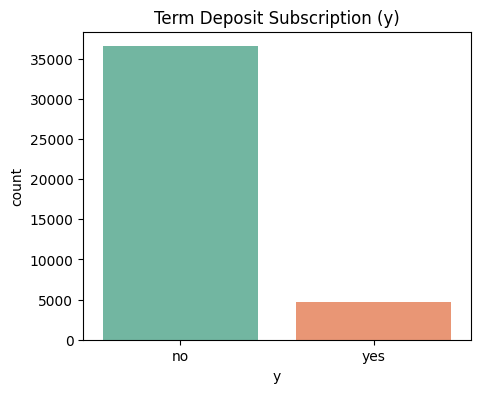

y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [23]:
plt.figure(figsize=(5, 4))
sns.countplot(x='y', data=df, palette='Set2')
plt.title("Term Deposit Subscription (y)")
plt.show()
print(df['y'].value_counts(normalize=True).mul(100).round(2))

#### Barplot
#### Chart - 2 : Subscription Rate by Job

job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.91
management       11.22
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: y, dtype: float64


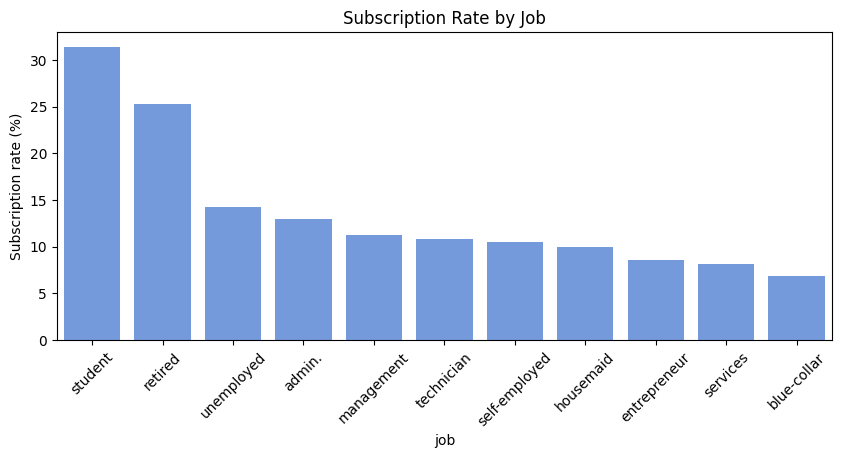

In [24]:
job_rate = (df.groupby('job')['y'].apply(lambda s: (s == 'yes').mean() * 100)
              .sort_values(ascending=False))
print(job_rate.round(2))

plt.figure(figsize=(10, 4))
sns.barplot(x=job_rate.index, y=job_rate.values, color="cornflowerblue")
plt.xticks(rotation=45)
plt.ylabel("Subscription rate (%)")
plt.title("Subscription Rate by Job")
plt.show()

#### Explanation (Charts 1 and 2)

##### 1. Why did you pick the specific chart?

A **countplot** was used for the target variable because it shows the number of customers in each class (yes / no) and exposes any class imbalance at a glance. A **barplot of subscription rate by job** was used because it compares one metric (the percentage who subscribed) across many categories, and using rates instead of raw counts keeps large job groups from looking more important only because they have more customers.

##### 2. What is/are the insight(s) found from the chart?

1. **Class imbalance:** About **89% of calls ended in "no"** and only about **11% in "yes"**. A model that always predicts "no" would be about 89% accurate and still useless, so Precision, Recall, F1-score and ROC-AUC must be used, and the imbalance must be handled during modelling.
2. **Job matters:** **Students (about 31%)** and **retired customers (about 25%)** subscribe at more than double the overall rate. Unemployed (about 14%) and admin (about 13%) come next. **Blue-collar (about 7%), services (about 8%) and entrepreneur (about 8.5%)** subscribe the least.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** The imbalance tells the team that random calling wastes most of its effort, since about 9 in 10 calls fail. Prioritising high-conversion segments such as students and retired customers can raise the success rate per call and lower campaign cost.

**Negative growth risk:** Students and retirees are small groups, so focusing only on them would limit total subscriptions. Blue-collar and services customers have low rates but make up a large share of the customer base, so ignoring them entirely would leave volume untapped. They need a different offer or channel rather than being dropped.

#### Chart - 3 : Subscription Rate by Previous Campaign Outcome (poutcome)

poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64


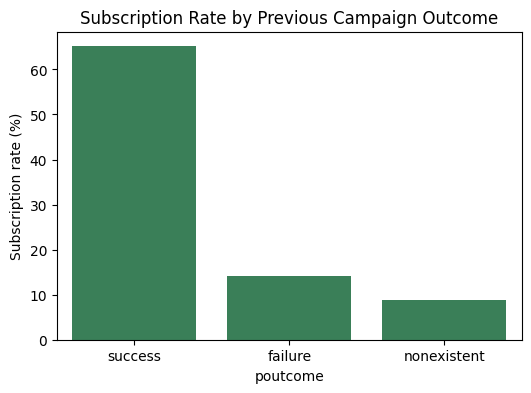

In [25]:
pout_rate = (df.groupby('poutcome')['y'].apply(lambda s: (s == 'yes').mean() * 100)
               .sort_values(ascending=False))
print(pout_rate.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=pout_rate.index, y=pout_rate.values, color="seagreen")
plt.ylabel("Subscription rate (%)")
plt.title("Subscription Rate by Previous Campaign Outcome")
plt.show()

#### Chart - 4 : Subscription Rate by Contact Type

contact
cellular     14.74
telephone     5.23
Name: y, dtype: float64


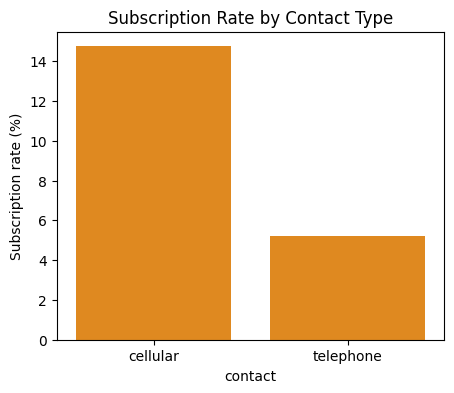

In [26]:
contact_rate = (df.groupby('contact')['y'].apply(lambda s: (s == 'yes').mean() * 100)
                  .sort_values(ascending=False))
print(contact_rate.round(2))

plt.figure(figsize=(5, 4))
sns.barplot(x=contact_rate.index, y=contact_rate.values, color="darkorange")
plt.ylabel("Subscription rate (%)")
plt.title("Subscription Rate by Contact Type")
plt.show()

#### Explanation (Charts 3 and 4)

##### 1. Why did you pick the specific chart?

**Barplots of subscription rate** were used for both variables because each has only a few categories and the goal is to compare one metric (the percentage who subscribed) across them. Using rates instead of raw counts keeps large groups, such as "nonexistent" outcomes or cellular contacts, from looking more important just because they contain more customers.

##### 2. What is/are the insight(s) found from the chart?

1. **Previous outcome is a very strong signal:** Customers whose previous campaign was a **success subscribed at about 65%**, compared with about **14% after a failure** and only about **9% for customers never contacted before** ("nonexistent"). A past success makes a new subscription about 7 times more likely than the no-history group.
2. **Contact type matters:** **Cellular contacts subscribed at about 15%**, against about **5% for telephone (landline) contacts**, nearly three times higher. Part of this gap may also reflect when each channel was used during the campaign, so it should be read as a strong association rather than proof that the channel alone causes the difference.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** Customers with a successful previous campaign are the best targets for repeat offers, and they should be called first. Shifting calls from landline to cellular numbers can raise the conversion rate per call without extra cost.

**Negative growth risk:** Previous-campaign successes are a small group (most customers have no history), so relying only on them would shrink the audience. Likewise, abandoning landline contacts entirely would lose customers who are only reachable that way. The better plan is to prioritise these segments while still running a tested offer for new customers.

#### Histplot
#### Chart - 5 : Age Distribution by Subscription

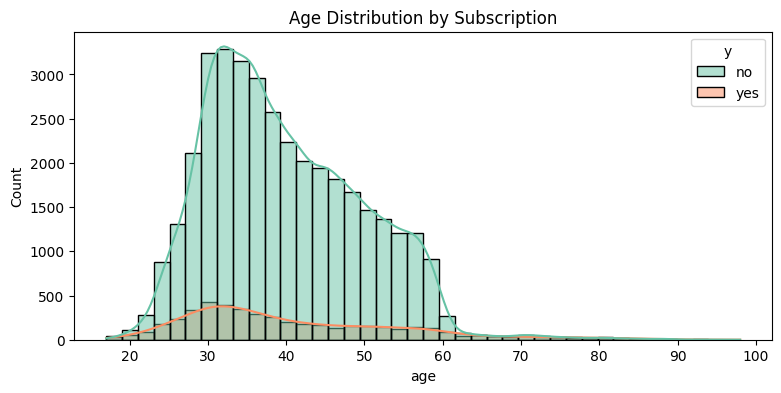

       count   mean    std   min   25%   50%   75%   max
y                                                       
no   36537.0  39.91   9.90  17.0  32.0  38.0  47.0  95.0
yes   4639.0  40.91  13.84  17.0  31.0  37.0  50.0  98.0


In [27]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x='age', hue='y', bins=40, kde=True, palette='Set2')
plt.title("Age Distribution by Subscription")
plt.show()
print(df.groupby('y')['age'].describe().round(2))

#### Chart - 6 : Subscription Rate by Month

month
mar    50.55
apr    20.49
may     6.44
jun    10.51
jul     9.04
aug    10.61
sep    44.91
oct    43.93
nov    10.15
dec    48.90
Name: y, dtype: float64


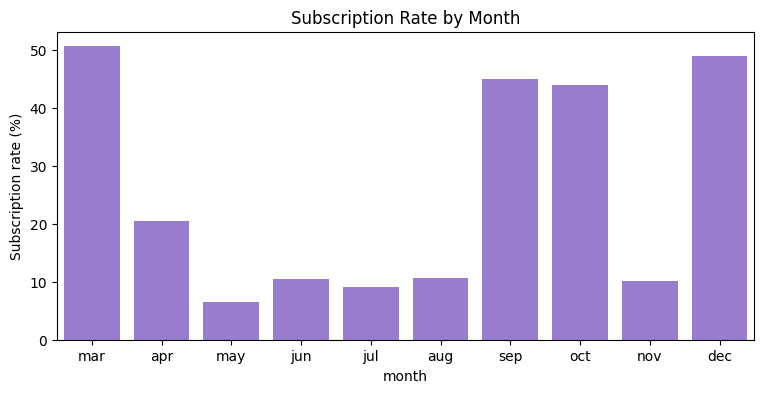

In [28]:
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_rate = (df.groupby('month')['y'].apply(lambda s: (s == 'yes').mean() * 100)
                .reindex(month_order))
print(month_rate.round(2))

plt.figure(figsize=(9, 4))
sns.barplot(x=month_rate.index, y=month_rate.values, color="mediumpurple")
plt.ylabel("Subscription rate (%)")
plt.title("Subscription Rate by Month")
plt.show()

#### Explanation (Charts 5 and 6)

##### 1. Why did you pick the specific chart?

A **histogram with a KDE curve, split by the target**, was used for `age` because age is a continuous variable, and the histogram shows its distribution shape while the colour split shows how subscribers differ from non-subscribers. A **barplot of subscription rate by month** was used because month is a categorical variable and the goal is to compare the conversion rate across months. The months were put in calendar order so seasonal patterns are easy to read.

##### 2. What is/are the insight(s) found from the chart?

1. **Age:** Both subscribers and non-subscribers are concentrated between about **25 and 45 years**, with a peak around 30 to 35, so most of the contacted customers are working-age. The distribution is right-skewed, with a long thin tail up to 98. Above about 60, subscribers make up a noticeably larger share of the customers than in the middle ages, which fits the high subscription rate seen earlier for retired customers.
2. **Month:** Subscription rates vary strongly by month. **March (about 50%), December (about 49%), September (about 45%) and October (about 44%)** are far above the rest. **April is about 20%**, while **May (about 6.5%), June, July, August and November (about 9% to 11%)** are the lowest.
3. **Caution:** The very high-rate months (March, September, October, December) appear to have far fewer calls than the low-rate summer months, so their percentages are based on small samples and should be read as indicative, not exact.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** Campaign timing can be planned around the months where customers respond best, and the age profile shows which groups to include in call lists. Concentrating effort in high-response months and on the 25 to 45 and 60+ age groups can raise the success rate per call.

**Negative growth risk:** The high-response months have small call volumes, so shifting the whole campaign into them is not guaranteed to keep the same rates. Also, the weakest months (such as May) carry the largest call volume, so cutting them completely would reduce total subscriptions. The better approach is to test more calls in the high-response months while improving the offer in the low-response ones.

#### Boxplot
#### Chart - 7 : Euribor 3-Month Rate vs Subscription

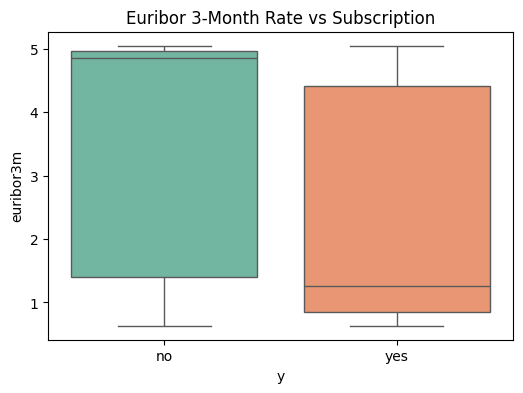

       count  mean   std   min   25%   50%   75%   max
y                                                     
no   36537.0  3.81  1.64  0.63  1.40  4.86  4.96  5.04
yes   4639.0  2.12  1.74  0.63  0.85  1.27  4.41  5.04


In [29]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='y', y='euribor3m', data=df, palette='Set2')
plt.title("Euribor 3-Month Rate vs Subscription")
plt.show()
print(df.groupby('y')['euribor3m'].describe().round(2))

#### Chart - 8 : Number of Contacts in This Campaign vs Subscription

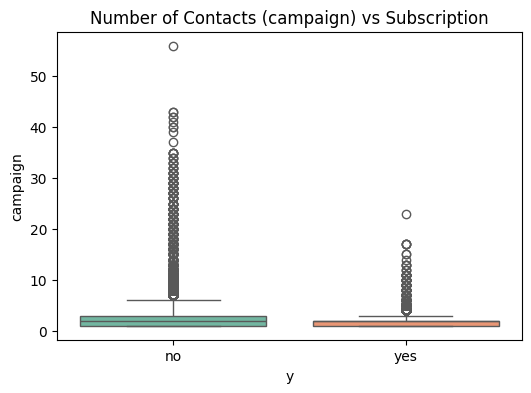

       count  mean   std  min  25%  50%  75%   max
y                                                 
no   36537.0  2.63  2.87  1.0  1.0  2.0  3.0  56.0
yes   4639.0  2.05  1.67  1.0  1.0  2.0  2.0  23.0


In [30]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='y', y='campaign', data=df, palette='Set2')
plt.title("Number of Contacts (campaign) vs Subscription")
plt.show()
print(df.groupby('y')['campaign'].describe().round(2))

#### Explanation (Charts 7 and 8)

##### 1. Why did you pick the specific chart?

**Boxplots** were used because they compare the distribution of a numeric variable (`euribor3m` and `campaign`) between two groups (subscribers and non-subscribers). They show the median, the spread (quartiles) and the outliers in one view, which a simple average would hide.

##### 2. What is/are the insight(s) found from the chart?

1. **Euribor 3-month rate:** Non-subscribers were mostly contacted when the rate was high (median about **4.9**, most values between about 1.4 and 5.0). Subscribers have a much lower median of about **1.3**, and half of them were contacted when the rate was below about 1.3. Subscriptions are therefore clearly more common in periods of low interest rates.
2. **Number of contacts (campaign):** Both groups have a median of only about **1 to 2 contacts**, but non-subscribers have a long tail of outliers, with some customers called **up to 56 times**. Subscribers rarely exceed about 10 contacts, with a maximum of about 23. Repeated calling does not appear to convert customers; the customers who say yes usually do so within the first few calls.
3. **Caution:** Euribor is a market-wide indicator that changes over time, so it also reflects when each call was made, not just customer behaviour. It should be read as a strong association, not proof of cause.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** The bank can time campaigns for periods of low interest rates, when customers respond best. It can also cap the number of calls per customer (for example at 3 to 5), because extra attempts rarely produce a subscription and only add cost and customer annoyance.

**Negative growth risk:** Interest rates are outside the bank's control, so waiting for low-rate periods may delay revenue. A hard call limit could also stop a few late conversions. The `campaign` outliers also need treatment before modelling, so that a few extreme values do not distort the model.

#### Chart - 9 : Subscription Rate by Education

education
illiterate             22.22
university.degree      13.82
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.21
basic.9y                7.82
Name: y, dtype: float64


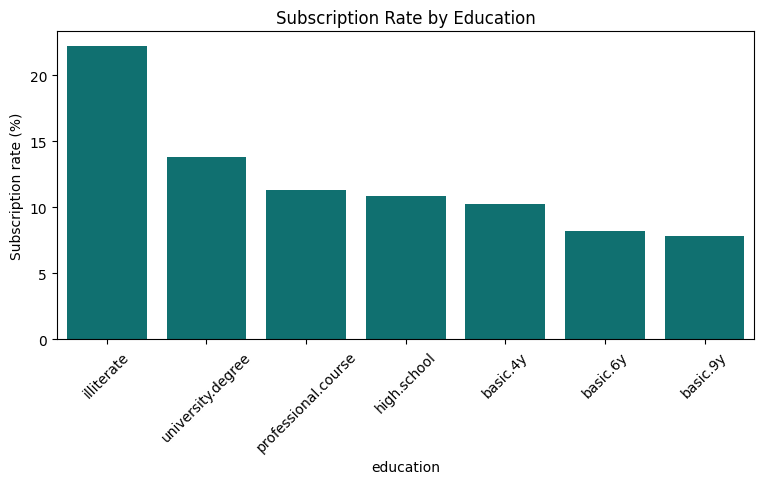

In [31]:
edu_rate = (df.groupby('education')['y'].apply(lambda s: (s == 'yes').mean() * 100)
              .sort_values(ascending=False))
print(edu_rate.round(2))

plt.figure(figsize=(9, 4))
sns.barplot(x=edu_rate.index, y=edu_rate.values, color="teal")
plt.xticks(rotation=45)
plt.ylabel("Subscription rate (%)")
plt.title("Subscription Rate by Education")
plt.show()

#### Correlation Heatmap
#### Chart - 10 : Correlation Between Numeric Features

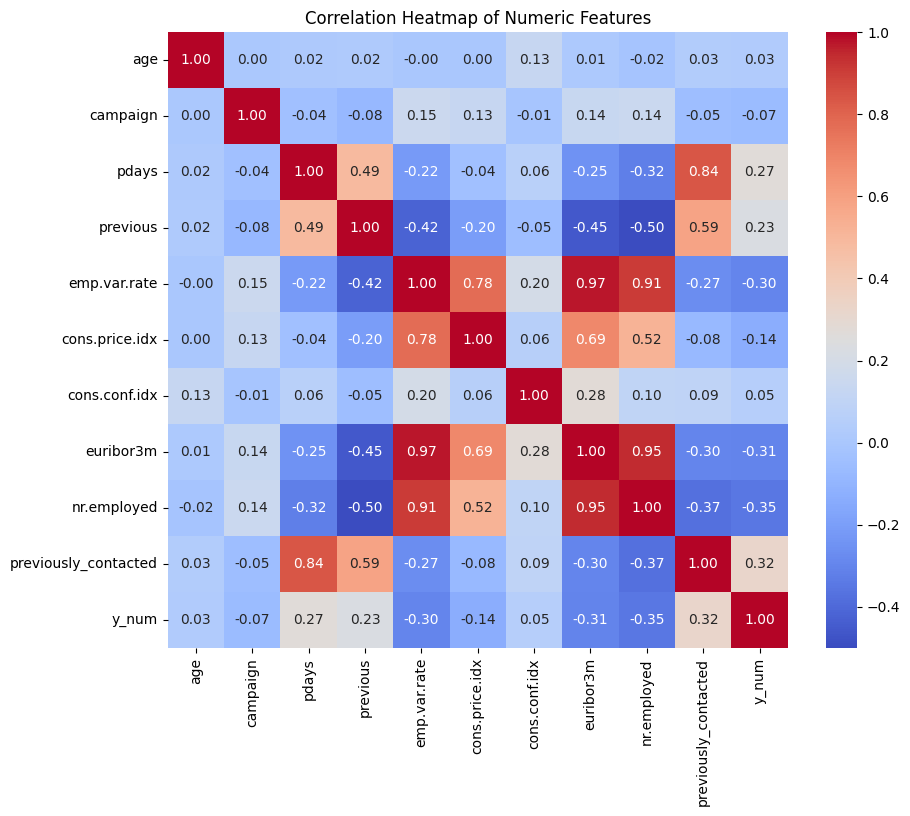

y_num                   1.000
previously_contacted    0.325
pdays                   0.267
previous                0.230
cons.conf.idx           0.055
age                     0.030
campaign               -0.066
cons.price.idx         -0.136
emp.var.rate           -0.298
euribor3m              -0.308
nr.employed            -0.355
Name: y_num, dtype: float64


In [32]:
corr_df = df.copy()
corr_df['y_num'] = (corr_df['y'] == 'yes').astype(int)
num_corr = corr_df.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()
print(num_corr['y_num'].sort_values(ascending=False).round(3))

#### Explanation (Charts 9 and 10)

##### 1. Why did you pick the specific chart?

A **barplot of subscription rate by education** was used because education is a categorical variable and the goal is to compare the conversion rate across its levels. A **correlation heatmap** was used because it summarises the linear relationship between every pair of numeric variables in one view. It shows which features move with the target `y`, and which features are strongly related to each other (multicollinearity), which matters when choosing and preparing features for modelling.

##### 2. What is/are the insight(s) found from the chart?

1. **Education:** Subscription rises with higher education. **University degree holders subscribe at about 14%**, followed by professional course (about 11%) and high school (about 11%). The basic education groups are lowest, at about **8% for basic.6y and basic.9y**. The illiterate group shows the highest rate (about 22%), but it is a very small group, so that figure is unreliable and should not drive decisions.
2. **Correlation with the target:** No numeric feature has a strong linear link with `y`. The strongest are **nr.employed (about -0.35), previously_contacted (about +0.32), euribor3m (about -0.31), emp.var.rate (about -0.30), pdays (about +0.27) and previous (about +0.23)**. `age` (0.03) and `cons.conf.idx` (0.05) are almost unrelated to the target in a linear sense.
3. **Multicollinearity:** Several features are highly correlated with each other: **emp.var.rate and euribor3m (0.97), euribor3m and nr.employed (0.95), emp.var.rate and nr.employed (0.91), emp.var.rate and cons.price.idx (0.78)**. These economic indicators move together and carry overlapping information. `pdays` and `previously_contacted` (0.84) are also related, because the second was created from the first.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** Higher-education customers respond better, so they can be prioritised in call lists and offered products suited to them. The correlation results tell the data team which features matter most (economic indicators and previous-contact history) and which are redundant, so the model can be built on a cleaner feature set.

**Negative growth risk:** Education alone is a weak basis for targeting, because the differences between levels are modest and the largest segments (basic and high school) still hold many customers. The highly correlated economic features can make linear models unstable and hard to interpret if all of them are kept, so some should be removed or handled with regularisation. Correlation only measures linear links, so non-linear patterns (such as the month effect) are not captured here.

#### Chart - 11 : Subscription Rate by Housing Loan, Personal Loan and Default

housing {'no': 10.88, 'yes': 11.59}
loan {'no': 11.33, 'yes': 10.93}
default {'no': 12.88, 'unknown': 5.15, 'yes': 0.0}


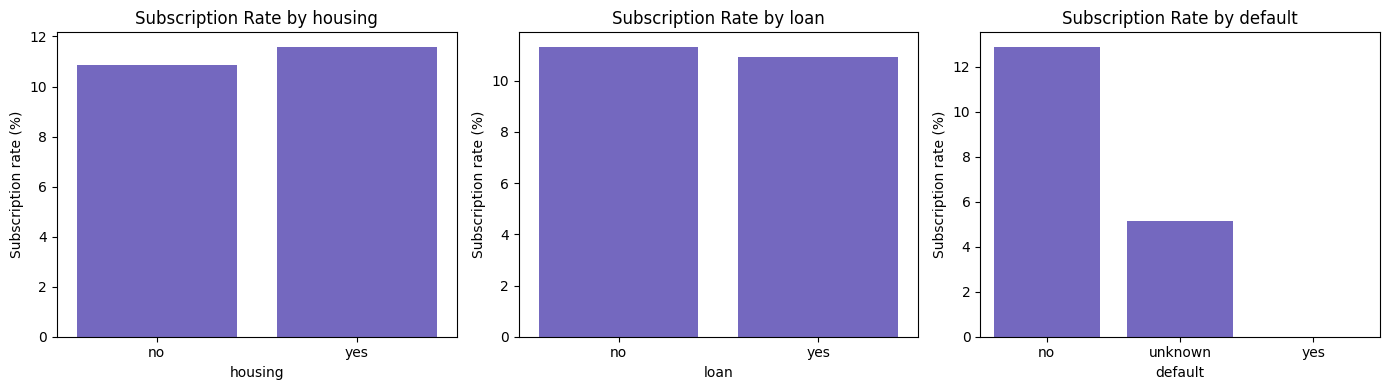

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['housing', 'loan', 'default']):
    rate = df.groupby(col)['y'].apply(lambda s: (s == 'yes').mean() * 100)
    print(col, rate.round(2).to_dict())
    sns.barplot(x=rate.index, y=rate.values, color="slateblue", ax=ax)
    ax.set_title(f"Subscription Rate by {col}")
    ax.set_ylabel("Subscription rate (%)")
plt.tight_layout()
plt.show()

#### Chart - 12 : Outlier Detector

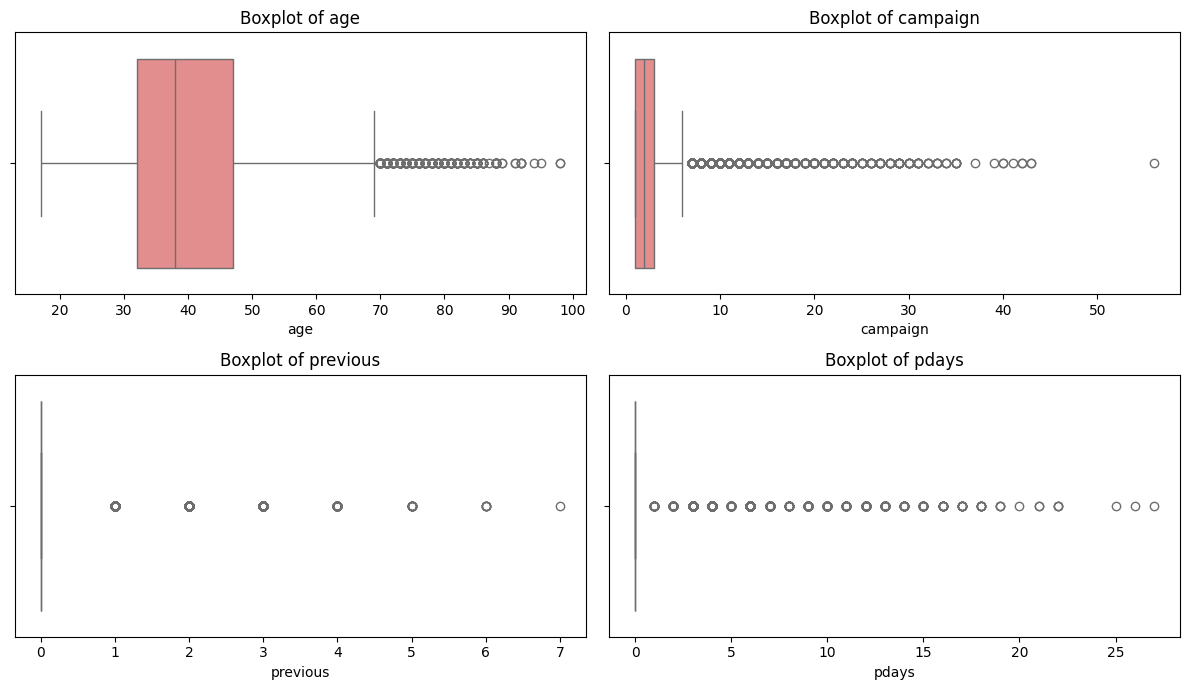

In [34]:
check = ['age', 'campaign', 'previous', 'pdays']
plt.figure(figsize=(12, 7))
for i, col in enumerate(check, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df[col], color="lightcoral")
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

#### Explanation (Charts 11 and 12)

##### 1. Why did you pick the specific chart?

**Side-by-side barplots of subscription rate** were used for `housing`, `loan` and `default` because all three are categorical variables with two or three levels, and plotting them on one row makes the differences between them easy to compare. **Boxplots** were used as an outlier detector for `age`, `campaign`, `previous` and `pdays` because they mark every point beyond the whiskers (1.5 times the interquartile range) as a potential outlier in a single view.

##### 2. What is/are the insight(s) found from the chart?

1. **Housing loan and personal loan have almost no effect:** Customers with and without a housing loan subscribe at about **11%** (roughly 10.9% vs 11.6%), and the same holds for personal loans (roughly 11.3% vs 10.9%). These two features are weak predictors on their own.
2. **Default status matters:** Customers with **no credit default subscribe at about 13%**, while those with an **unknown** default status subscribe at only about **5%**. The "yes" group shows essentially no subscriptions, but it contains only a handful of customers, so that result is not reliable. This supports keeping "unknown" as its own category, since it behaves differently from "no".
3. **Outliers:**
   - `age` has outliers above about **69 years**, up to 98.
   - `campaign` has many outliers above about **6 contacts**, up to 56.
   - `previous` and `pdays` are zero for most customers, so every non-zero value is flagged as an outlier. These are valid values for customers with earlier contact, not errors.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** Since existing loans barely change the response, the bank does not need to exclude customers who already hold a housing or personal loan, which keeps the call list large. Customers with a clean default record respond better and should be preferred, while those with an unknown default status can be deprioritised. Detecting outliers early protects the model from a few extreme records, such as customers called more than 40 times.

**Negative growth risk:** Treating every outlier as an error would delete genuine information. The non-zero values of `previous` and `pdays` identify the previously contacted customers, who are among the best prospects, so removing or capping them would hurt the model. Extreme `campaign` values are real but add little, so they are handled by capping rather than deletion.

#### Chart - 13 : Subscription Rate by Marital Status and Day of Week

marital
divorced    10.32
married     10.17
single      14.01
Name: y, dtype: float64
day_of_week
mon     9.95
tue    11.79
wed    11.67
thu    12.11
fri    10.81
Name: y, dtype: float64


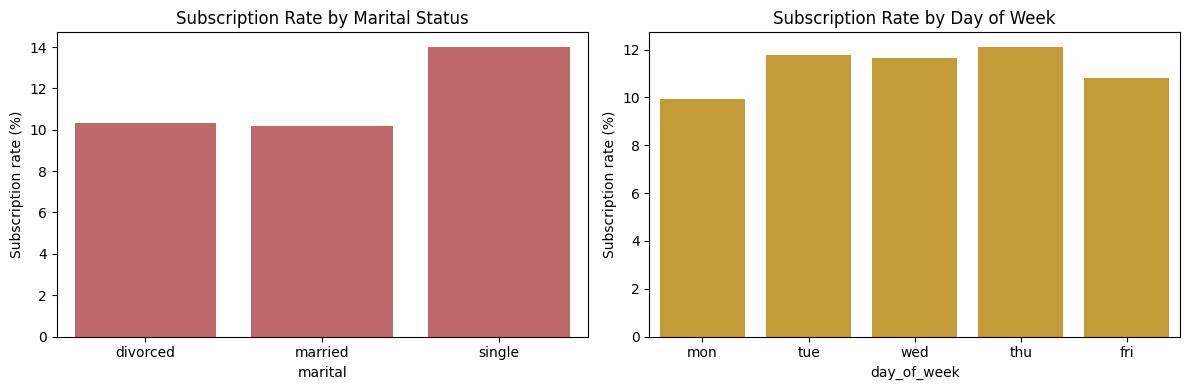

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

marital_rate = df.groupby('marital')['y'].apply(lambda s: (s == 'yes').mean() * 100)
print(marital_rate.round(2))
sns.barplot(x=marital_rate.index, y=marital_rate.values, color="indianred", ax=axes[0])
axes[0].set_title("Subscription Rate by Marital Status")
axes[0].set_ylabel("Subscription rate (%)")

day_order = ['mon', 'tue', 'wed', 'thu', 'fri']
day_rate = (df.groupby('day_of_week')['y'].apply(lambda s: (s == 'yes').mean() * 100)
              .reindex(day_order))
print(day_rate.round(2))
sns.barplot(x=day_rate.index, y=day_rate.values, color="goldenrod", ax=axes[1])
axes[1].set_title("Subscription Rate by Day of Week")
axes[1].set_ylabel("Subscription rate (%)")

plt.tight_layout()
plt.show()

#### Pairplot
#### Chart - 14 : Pairplot of Key Numeric Features

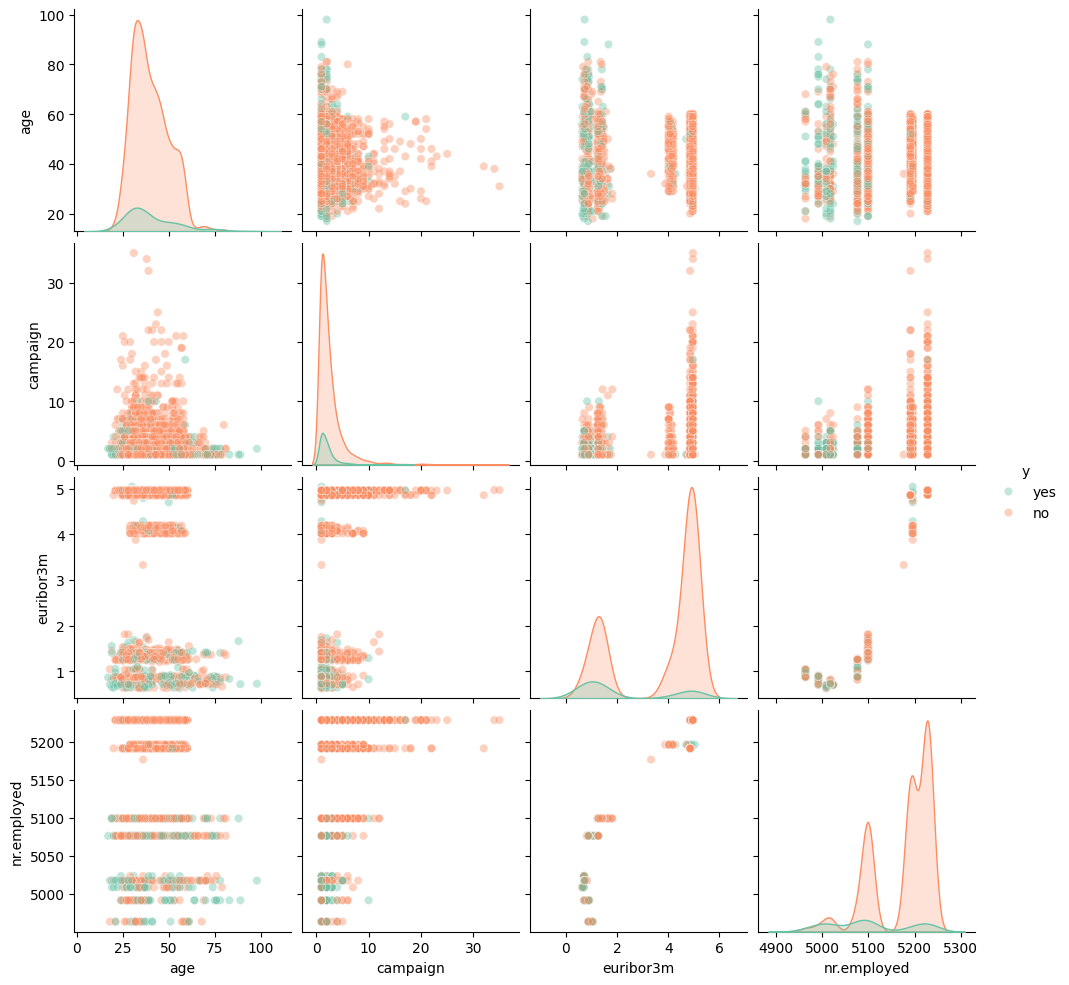

In [36]:
pair_cols = ['age', 'campaign', 'euribor3m', 'nr.employed', 'y']
sns.pairplot(df[pair_cols].sample(3000, random_state=42), hue='y',
             palette='Set2', plot_kws={'alpha': 0.4})
plt.show()

#### Explanation (Charts 13 and 14)

##### 1. Why did you pick the specific chart?

**Side-by-side barplots of subscription rate** were used for `marital` and `day_of_week` because both are categorical variables with few levels, and comparing rates keeps larger groups from looking more important just because they have more customers. A **pairplot** was used as a final multivariate check because it shows the distribution of each key numeric feature (diagonal) and the relationship between every pair of them (off-diagonal), with colour showing subscribers versus non-subscribers.

##### 2. What is/are the insight(s) found from the chart?

1. **Marital status:** **Single customers subscribe at about 14%**, against about **10% for married and divorced customers**, so single customers respond noticeably better.
2. **Day of week:** The differences are small. **Thursday (about 12%), Tuesday and Wednesday (about 11.7%)** are slightly higher, while **Monday is the lowest (about 10%)**. Day of the call is a weak factor.
3. **Pairplot:** No pair of features separates subscribers from non-subscribers with a clear line, which means a simple linear boundary will not be enough. Subscribers (green) cluster at **low `euribor3m` (below about 2)** and **low `nr.employed` (below about 5,100)**, while the high-value clusters are mostly non-subscribers. High `campaign` values (above about 10) are almost all non-subscribers. `age` shows no clear separation. `euribor3m` and `nr.employed` appear as a few separate clusters because they are quarterly or daily indicators repeated across many calls.
4. **Class imbalance is visible again:** the non-subscriber points and curves dominate every panel.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** Single customers are a better target group for the term deposit offer, and the weekday pattern suggests that Tuesday to Thursday calls give a small advantage over Monday and Friday. The pairplot confirms that economic conditions (low interest rate and low employment periods) and the number of contacts are the main drivers, so campaign timing and call limits should be planned around them. It also suggests that non-linear models (tree-based and boosting models) may work better than simple linear ones.

## Section 5: Hypothesis Testing

### Hypothetical Statement - 1
#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** Contact type (cellular / telephone) and subscription (`y`) are independent, so the subscription rate is the same for both.

**Alternate hypothesis (H1):** Contact type and subscription are not independent, so the subscription rate differs between cellular and telephone contacts.

#### 2. Perform an appropriate statistical test.

In [37]:
# Chi-square test of independence: contact vs y
contingency = pd.crosstab(df['contact'], df['y'])
print(contingency)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
print("Chi-square statistic:", round(chi2, 2))
print("P-value:", p_value)

alpha = 0.05
if p_value < alpha:
    print("Reject H0: contact type and subscription are related.")
else:
    print("Fail to reject H0: no significant relationship found.")

y             no   yes
contact               
cellular   22283  3852
telephone  14254   787
Chi-square statistic: 862.08
P-value: 1.7187406241263769e-189
Reject H0: contact type and subscription are related.


##### 3. Which statistical test have you done to obtain P-Value?

A **Chi-square test of independence**.

##### 4. Why did you choose the specific statistical test?

Both `contact` and `y` are categorical variables, and the Chi-square test of independence is the standard way to check whether two categorical variables are related. The earlier barplot already showed a large gap between cellular (about 15%) and telephone (about 5%) subscription rates, so the test confirms whether that gap is statistically significant.

**Result:** The Chi-square statistic is 862.08 and the p-value is about 1.7e-189, far below 0.05, so **H0 is rejected**. Contact type and subscription are related. Cellular contacts subscribed at about **14.7%** (3,852 of 26,135) against about **5.2%** for telephone contacts (787 of 15,041). Cellular contact should be preferred in future campaigns.

### Hypothetical Statement - 2
#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** The mean 3-month Euribor rate is the same for customers who subscribed and customers who did not.

**Alternate hypothesis (H1):** The mean 3-month Euribor rate differs between subscribers and non-subscribers.

#### 2. Perform an appropriate statistical test.

In [38]:
# Welch's independent two-sample t-test: euribor3m for yes vs no
yes_group = df.loc[df['y'] == 'yes', 'euribor3m']
no_group = df.loc[df['y'] == 'no', 'euribor3m']

print("Mean euribor3m (yes):", round(yes_group.mean(), 3))
print("Mean euribor3m (no):", round(no_group.mean(), 3))

t_stat, p_value = stats.ttest_ind(yes_group, no_group, equal_var=False)
print("T-statistic:", round(t_stat, 2))
print("P-value:", p_value)

alpha = 0.05
if p_value < alpha:
    print("Reject H0: mean Euribor differs between subscribers and non-subscribers.")
else:
    print("Fail to reject H0: no significant difference found.")

Mean euribor3m (yes): 2.123
Mean euribor3m (no): 3.811
T-statistic: -62.56
P-value: 0.0
Reject H0: mean Euribor differs between subscribers and non-subscribers.


##### 3. Which statistical test have you done to obtain P-Value?

**Welch's independent two-sample t-test**.

##### 4. Why did you choose the specific statistical test?

The goal was to compare the mean of one numeric variable (`euribor3m`) between exactly two independent groups (subscribers and non-subscribers). Welch's version of the t-test was chosen because it does not assume equal variances and the two groups have very different sizes (about 4,600 versus 36,500). The boxplot showed clearly different medians, so the test checks whether the difference is statistically significant.

**Result:** The mean Euribor rate is **2.12 for subscribers** and **3.81 for non-subscribers**. The t-statistic is -62.56 and the p-value is 0.0 (below the numerical precision of the computer), so **H0 is rejected**. Customers subscribe much more often when interest rates are low, so the Euribor rate is an important predictor and campaign timing should take it into account.

### Hypothetical Statement - 3
#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** The distribution of the number of contacts (`campaign`) is the same for subscribers and non-subscribers.

**Alternate hypothesis (H1):** The distribution of the number of contacts differs between subscribers and non-subscribers.

#### 2. Perform an appropriate statistical test.

In [39]:
# Mann-Whitney U test: campaign for yes vs no
yes_camp = df.loc[df['y'] == 'yes', 'campaign']
no_camp = df.loc[df['y'] == 'no', 'campaign']

print("Median campaign (yes):", yes_camp.median())
print("Median campaign (no):", no_camp.median())

u_stat, p_value = stats.mannwhitneyu(yes_camp, no_camp, alternative='two-sided')
print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05
if p_value < alpha:
    print("Reject H0: number of contacts differs between subscribers and non-subscribers.")
else:
    print("Fail to reject H0: no significant difference found.")

Median campaign (yes): 2.0
Median campaign (no): 2.0
U-statistic: 75391969.5
P-value: 3.6293827168458346e-38
Reject H0: number of contacts differs between subscribers and non-subscribers.


##### 3. Which statistical test have you done to obtain P-Value?

The **Mann-Whitney U test**.

##### 4. Why did you choose the specific statistical test?

The goal was to compare a numeric variable (`campaign`) between two independent groups, but `campaign` is heavily right-skewed with extreme outliers (up to 56 contacts), as seen in the histogram and boxplots. A t-test assumes roughly normal data, so the non-parametric Mann-Whitney U test was chosen. It compares the ranks of the values and is not distorted by outliers.

**Result:** The p-value is about 3.6e-38, so **H0 is rejected** and the distribution of the number of contacts differs between the two groups. However, the **median is 2 for both groups**, so the practical difference is small. With more than 41,000 rows even a small difference becomes statistically significant. The boxplot showed that the real gap is in the tail: non-subscribers include customers called up to 56 times, while subscribers rarely need more than a few calls. This supports setting a limit on calls per customer.

### Hypothetical Statement - 4
#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** The outcome of the previous campaign (`poutcome`) and subscription (`y`) are independent.

**Alternate hypothesis (H1):** The outcome of the previous campaign and subscription are not independent.

#### 2. Perform an appropriate statistical test.

In [40]:
# Chi-square test of independence: poutcome vs y
contingency2 = pd.crosstab(df['poutcome'], df['y'])
print(contingency2)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency2)
print("Chi-square statistic:", round(chi2, 2))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

alpha = 0.05
if p_value < alpha:
    print("Reject H0: previous outcome and subscription are related.")
else:
    print("Fail to reject H0: no significant relationship found.")

y               no   yes
poutcome                
failure       3647   605
nonexistent  32411  3140
success        479   894
Chi-square statistic: 4230.14
Degrees of freedom: 2
P-value: 0.0
Reject H0: previous outcome and subscription are related.


##### 3. Which statistical test have you done to obtain P-Value?

A **Chi-square test of independence**.

##### 4. Why did you choose the specific statistical test?

Both `poutcome` (success / failure / nonexistent) and `y` (yes / no) are categorical variables, so the Chi-square test of independence is the appropriate test. The earlier barplot showed a subscription rate of about 65% after a previous success against about 9% for customers with no history, so the test checks whether that large difference is statistically significant.

**Result:** The Chi-square statistic is 4,230.14 with 2 degrees of freedom and a p-value of 0.0, so **H0 is rejected**. The previous campaign outcome is strongly related to subscription. Customers with a previous **success subscribed at about 65.1%** (894 of 1,373), compared with about **14.2% after a failure** (605 of 4,252) and about **8.8% with no previous contact** (3,140 of 35,551). Previous successes are the highest-value prospects.

### Summary of Hypothesis Testing

All four hypotheses were rejected at the 5% significance level:
- Contact type, previous campaign outcome and the Euribor rate each have a strong, statistically significant link with subscription.
- The number of contacts differs significantly between groups, but the practical gap is small (equal medians), so it is a weaker driver.

These results confirm the patterns seen in the charts and support keeping these features for modelling.

## Section 6: Feature Engineering and Data Pre-processing

### 1. Handling Outliers

In [41]:
# Cap extreme values using the IQR method (winsorizing instead of deleting rows)
def cap_outliers_iqr(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return series.clip(lower=lower, upper=upper)

print("Before capping -> age max:", df['age'].max(), "| campaign max:", df['campaign'].max())

for col in ['age', 'campaign']:
    df[col] = cap_outliers_iqr(df[col])

print("After capping  -> age max:", df['age'].max(), "| campaign max:", df['campaign'].max())

Before capping -> age max: 98 | campaign max: 56
After capping  -> age max: 69.5 | campaign max: 6


#### What all outlier treatment techniques have you used and why did you use those techniques?

**IQR-based capping (winsorizing)** was applied to `age` and `campaign`. Values beyond 1.5 times the interquartile range were replaced with the boundary value instead of being deleted. This keeps all 41,176 rows, including the rare subscribers, while stopping a few extreme values (customers aged 98, or called 56 times) from dominating the model.

`previous` and `pdays` were **not capped**. Both are zero for most customers, so their IQR is zero, and capping would turn every non-zero value into 0. That would erase the information about previously contacted customers, who are among the best prospects. Their non-zero values are valid data, not errors.

### 2. Categorical Encoding

In [42]:
df_encoded = df.copy()

# Target: yes -> 1, no -> 0
df_encoded['y'] = (df_encoded['y'] == 'yes').astype(int)

# Binary columns: yes/cellular -> 1, otherwise 0
df_encoded['housing'] = (df_encoded['housing'] == 'yes').astype(int)
df_encoded['loan'] = (df_encoded['loan'] == 'yes').astype(int)
df_encoded['contact'] = (df_encoded['contact'] == 'cellular').astype(int)

# Ordinal column: education has a natural order
edu_map = {'illiterate': 0, 'basic.4y': 1, 'basic.6y': 2, 'basic.9y': 3,
           'high.school': 4, 'professional.course': 5, 'university.degree': 6}
df_encoded['education'] = df_encoded['education'].map(edu_map)

# Nominal columns (no order): one-hot encoding
nominal_cols = ['job', 'marital', 'default', 'month', 'day_of_week', 'poutcome']
df_encoded = pd.get_dummies(df_encoded, columns=nominal_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_encoded.shape)
print("Any text columns left:", df_encoded.select_dtypes(include='object').columns.tolist())
print("Missing values:", df_encoded.isnull().sum().sum())
df_encoded.head()

Shape after encoding: (41176, 44)
Any text columns left: []
Missing values: 0


,age,education,housing,loan,contact,campaign,pdays,previous,emp.var.rate,cons.price.idx,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56.0,1,0,0,0,1,0,0,1.1,93.994,...,1,0,0,0,1,0,0,0,1,0
1,57.0,4,0,0,0,1,0,0,1.1,93.994,...,1,0,0,0,1,0,0,0,1,0
2,37.0,4,1,0,0,1,0,0,1.1,93.994,...,1,0,0,0,1,0,0,0,1,0
3,40.0,2,0,0,0,1,0,0,1.1,93.994,...,1,0,0,0,1,0,0,0,1,0
4,56.0,4,0,1,0,1,0,0,1.1,93.994,...,1,0,0,0,1,0,0,0,1,0


#### What all categorical encoding techniques have you used & why did you use those techniques?

Three techniques were used, matched to the type of each column:
1. **Binary encoding** for `housing`, `loan`, `contact` and the target `y`, which each have two values, so they become 0/1.
2. **Ordinal encoding** for `education`, which has a genuine order (illiterate < basic < high school < professional course < university degree). This keeps the "higher than" relationship that one-hot encoding would throw away.
3. **One-hot encoding** for `job`, `marital`, `default`, `month`, `day_of_week` and `poutcome`, which have no natural order. Label numbers (1, 2, 3) would wrongly suggest a ranking between unrelated categories. The first category of each column is dropped to avoid redundant columns.

### 3. Data Transformation

In [43]:
# Check skewness of numeric columns with a long right tail
skew_cols = ['campaign', 'age']
print("Skewness before:")
print(df_encoded[skew_cols].skew().round(2))

# log1p = log(1 + x): reduces right skew and is safe for zeros
df_encoded['campaign'] = np.log1p(df_encoded['campaign'])

print("\nSkewness after (campaign):", round(df_encoded['campaign'].skew(), 2))

Skewness before:
campaign    1.21
age         0.57
dtype: float64

Skewness after (campaign): 0.68


#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. After outlier capping, `campaign` was still right-skewed (**skewness 1.21**): most customers were contacted 1 to 3 times, with a tail up to 6. A **log transformation (`log1p`)** reduced the skewness to **0.68**, making the distribution more symmetric. This helps distance-based and linear models, and it does not harm tree-based models. `log1p` was chosen instead of a plain log because it handles values of 0 safely. `age` was only mildly skewed (**0.57**), so it was left unchanged.

### 4. Data Splitting

In [44]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("\nTrain target %:\n", y_train.value_counts(normalize=True).mul(100).round(2))
print("\nTest target %:\n", y_test.value_counts(normalize=True).mul(100).round(2))

Train shape: (32940, 43) | Test shape: (8236, 43)

Train target %:
 y
0    88.73
1    11.27
Name: proportion, dtype: float64

Test target %:
 y
0    88.73
1    11.27
Name: proportion, dtype: float64


#### What data splitting ratio have you used and why?

An **80/20 split** was used: about 32,900 rows for training and about 8,200 for testing. With 41,176 rows, 20% is large enough to give a stable estimate of test performance, while 80% leaves plenty of data to learn from. The split is **stratified** on the target `y`, so both sets keep the same 88.7% / 11.3% class ratio. Without stratification, the rare "yes" class could be unevenly distributed between the two sets. The data was split **before scaling and balancing** so that no information from the test set leaks into training.

### 5. Data Scaling

In [45]:
from sklearn.preprocessing import StandardScaler

num_cols = ['age', 'education', 'campaign', 'pdays', 'previous', 'emp.var.rate',
            'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit on training data only, then apply the same scaling to the test data
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(X_train_scaled[num_cols].describe().loc[['mean', 'std']].round(2))

      age  education  campaign  pdays  previous  emp.var.rate  cons.price.idx  \
mean  0.0       -0.0      -0.0    0.0       0.0          -0.0             0.0   
std   1.0        1.0       1.0    1.0       1.0           1.0             1.0   

      cons.conf.idx  euribor3m  nr.employed  
mean            0.0       -0.0          0.0  
std             1.0        1.0          1.0  


#### Which method have you used to scale you data and why?

**StandardScaler (z-score standardisation)** was used. It centres each numeric feature at mean 0 with standard deviation 1. The features were on very different scales (for example `nr.employed` is around 5,000 while `previous` is around 0.2), and scale-sensitive models such as Logistic Regression and SVM would otherwise be dominated by the large-valued columns.

Only the numeric columns were scaled; the 0/1 dummy columns were left unchanged. The scaler was **fitted on the training set only** and then applied to the test set, so no information from the test data leaks into training. Tree-based models are not affected by scaling, but using one consistent pipeline keeps the comparison fair.

### 6. Handling Class Imbalance

In [46]:
from imblearn.over_sampling import SMOTE

print("Before SMOTE (train):")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("\nAfter SMOTE (train):")
print(y_train_bal.value_counts())
print("\nBalanced train shape:", X_train_bal.shape)
print("Test set unchanged:", X_test_scaled.shape)

Before SMOTE (train):
y
0    29229
1     3711
Name: count, dtype: int64

After SMOTE (train):
y
0    29229
1    29229
Name: count, dtype: int64

Balanced train shape: (58458, 43)
Test set unchanged: (8236, 43)


#### Do you think the dataset is imbalanced? Explain Why.

Yes. Only **11.27%** of the customers subscribed, against 88.73% who did not. A model trained on this data can reach about 89% accuracy by always predicting "no", while finding none of the customers the bank actually wants to reach.

#### What technique did you use to handle the imbalance and why?

**SMOTE (Synthetic Minority Over-sampling Technique)** was applied to the **training set only**. It creates new synthetic "yes" examples by interpolating between existing "yes" customers and their nearest neighbours, instead of simply copying rows. This avoids the overfitting that plain duplication causes, and unlike under-sampling it does not throw away any of the 29,000 "no" examples.

The test set was left untouched, so the final scores reflect the real class ratio. Because the target is imbalanced, models are judged on Precision, Recall, F1-score and ROC-AUC and not on accuracy alone.

### 7. Dimensionality Reduction

Original features: 43
Components for 90% variance: 15
Components for 95% variance: 20


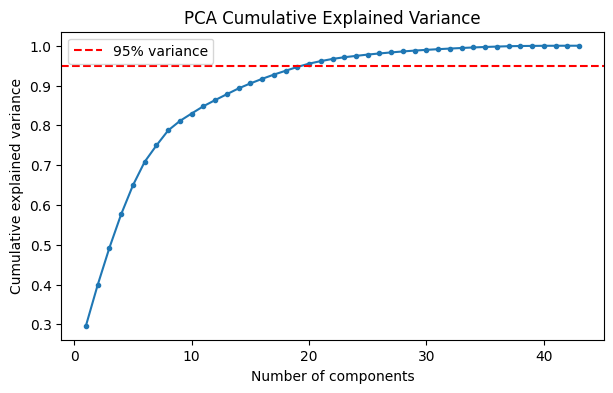

In [47]:
from sklearn.decomposition import PCA

pca = PCA().fit(X_train_scaled)
cum_var = pca.explained_variance_ratio_.cumsum()

n_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)
print("Original features:", X_train_scaled.shape[1])
print("Components for 90% variance:", n_90)
print("Components for 95% variance:", n_95)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=3)
plt.axhline(0.95, color='red', linestyle='--', label='95% variance')
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.show()

#### Do you think that dimensionality reduction is needed? Explain Why?

The dataset has **43 features** after encoding. The PCA curve shows that **15 components capture 90%** and **20 components capture 95%** of the variance, so a large part of the information is redundant. This matches the correlation heatmap, where the economic indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are correlated above 0.9. Dimensionality reduction is therefore possible, but it is not essential for the models used, because 43 features is manageable and tree-based models handle correlated features well.

#### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

**PCA (Principal Component Analysis)** was used as a **diagnostic only**, to see how much of the variance a smaller set of components captures. The original features were kept for modelling because PCA components are mixtures of the original columns, which destroys interpretability. The business goal is to explain *which* factors (previous outcome, contact type, interest rate) drive a subscription, and that would be lost.

## Section 7: ML Model Implementation

### Evaluation Setup
Models are trained on the SMOTE-balanced training set and evaluated on the untouched test set. Because only 11.3% of customers subscribe, accuracy alone is misleading, so **Precision, Recall, F1-score and ROC-AUC** are reported.

In [48]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

results = []   # every model adds one row here

def evaluate_model(name, model, X_te=X_test_scaled, y_te=y_test):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob),
    }
    results.append(row)
    print(classification_report(y_te, y_pred, target_names=["no", "yes"]))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred),
                           display_labels=["no", "yes"]).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()
    return row

### ML Model - 1 : Logistic Regression

              precision    recall  f1-score   support

          no       0.94      0.82      0.88      7308
         yes       0.29      0.56      0.38       928

    accuracy                           0.79      8236
   macro avg       0.61      0.69      0.63      8236
weighted avg       0.86      0.79      0.82      8236



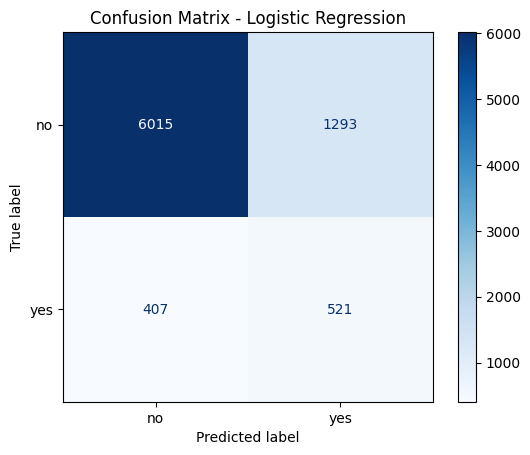

In [49]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_bal, y_train_bal)
_ = evaluate_model("Logistic Regression", lr)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Logistic Regression** is the interpretable baseline. It estimates the probability that a customer subscribes as a weighted combination of the features, and its coefficients show the direction of each factor's effect.

On the test set (8,236 customers, 928 of them real subscribers) it reached **Recall 0.56, Precision 0.29, F1 0.38 and ROC-AUC 0.747**. It finds a little over half of the real subscribers, but only about 3 in 10 flagged customers actually subscribe. Accuracy (0.79) is lower than the 88.7% "always no" baseline because training on SMOTE-balanced data shifts the model towards finding "yes" customers. This is the intended trade-off, so Recall, F1 and ROC-AUC are the metrics that matter here.

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__C': 0.001}
Best CV F1: 0.4273
              precision    recall  f1-score   support

          no       0.95      0.84      0.89      7308
         yes       0.34      0.65      0.45       928

    accuracy                           0.82      8236
   macro avg       0.65      0.75      0.67      8236
weighted avg       0.88      0.82      0.84      8236



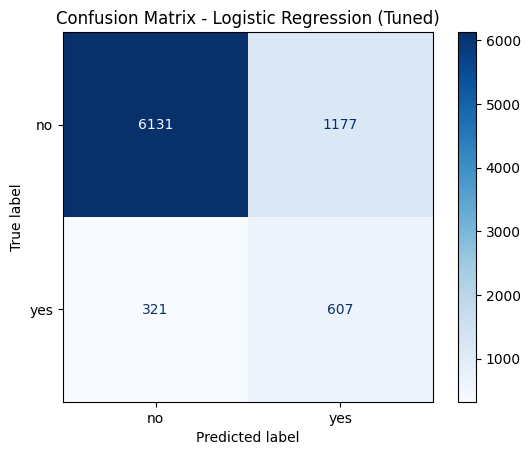

In [50]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipe_lr = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

param_grid_lr = {'clf__C': [0.0001, 0.001, 0.01]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv, scoring='f1', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

print("Best parameters:", grid_lr.best_params_)
print("Best CV F1:", round(grid_lr.best_score_, 4))

_ = evaluate_model("Logistic Regression (Tuned)", grid_lr.best_estimator_)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 3-fold stratified cross-validation** was used to search the regularisation strength `C`, scored on **F1**. F1 was chosen because accuracy is misleading on this imbalanced target. SMOTE was placed **inside the pipeline**, so synthetic samples are created only from each training fold and the validation fold stays untouched. This avoids data leakage and keeps the cross-validation score honest. The grid was first run over 0.01 to 10, then extended downwards because the best value sat at the edge. The final best value was **C = 0.001** (very strong regularisation), with a cross-validated F1 of **0.4273**. Strong regularisation helps here because many features are correlated (the economic indicators), and it keeps the coefficients stable.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a clear improvement. Recall rose from **0.56 to 0.65**, Precision from **0.29 to 0.34**, F1 from **0.38 to 0.45**, accuracy from **0.79 to 0.82** and ROC-AUC from **0.747 to 0.790**. Logistic Regression is a linear model, so there is a limit to what tuning `C` can do, which suggests that non-linear models should do better.

In [51]:
results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7936,0.2872,0.5614,0.3800,0.7468
1,Logistic Regression (Tuned),0.8181,0.3402,0.6541,0.4476,0.7898


### ML Model - 2 : Decision Tree

              precision    recall  f1-score   support

          no       0.94      0.91      0.93      7308
         yes       0.44      0.55      0.49       928

    accuracy                           0.87      8236
   macro avg       0.69      0.73      0.71      8236
weighted avg       0.89      0.87      0.88      8236



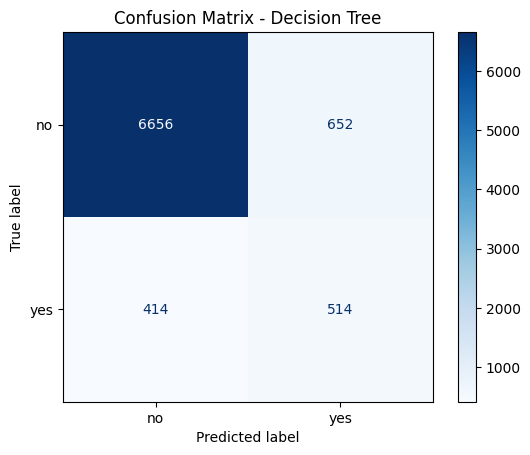

In [52]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=6, random_state=42)
dt.fit(X_train_bal, y_train_bal)
_ = evaluate_model("Decision Tree", dt)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Decision Tree** splits the customers with a series of yes/no questions (for example "was the previous campaign a success?" or "is the Euribor rate below 2?") and ends in a prediction. It captures non-linear patterns and interactions that Logistic Regression cannot, and its rules are easy to explain to a marketing team. The tree was limited to a depth of 6 to keep it from memorising the training data.

On the test set it reached **Recall 0.55, Precision 0.44, F1 0.49 and accuracy 0.87**. It found **514 of the 928 real subscribers** and wrongly flagged 652 customers, so about 44% of the customers it flags actually subscribe, compared with 34% for the tuned Logistic Regression. It misses more real subscribers (414, against about 320 for Logistic Regression), so it is the better choice when the cost of each call matters, and Logistic Regression is better when finding as many buyers as possible matters.

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 50}
Best CV F1: 0.4699
              precision    recall  f1-score   support

          no       0.94      0.88      0.91      7308
         yes       0.39      0.59      0.47       928

    accuracy                           0.85      8236
   macro avg       0.67      0.74      0.69      8236
weighted avg       0.88      0.85      0.86      8236



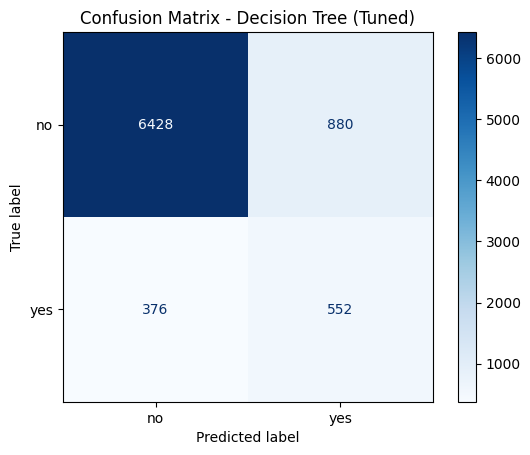

In [53]:
pipe_dt = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', DecisionTreeClassifier(random_state=42))
])

param_grid_dt = {
    'clf__max_depth': [3, 5, 7, 10],
    'clf__min_samples_leaf': [1, 20, 50, 100]
}

grid_dt = GridSearchCV(pipe_dt, param_grid_dt, cv=cv, scoring='f1', n_jobs=-1)
grid_dt.fit(X_train_scaled, y_train)

print("Best parameters:", grid_dt.best_params_)
print("Best CV F1:", round(grid_dt.best_score_, 4))

_ = evaluate_model("Decision Tree (Tuned)", grid_dt.best_estimator_)

In [54]:
results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7936,0.2872,0.5614,0.3800,0.7468
1,Logistic Regression (Tuned),0.8181,0.3402,0.6541,0.4476,0.7898
2,Decision Tree,0.8706,0.4408,0.5539,0.4909,0.7645
3,Decision Tree (Tuned),0.8475,0.3855,0.5948,0.4678,0.7759


##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 3-fold stratified cross-validation** was used to search the tree depth (3, 5, 7, 10) and the minimum number of samples per leaf (1, 20, 50, 100), scored on **F1**. A decision tree easily memorises the training data if it grows too deep, and these two parameters control exactly that, so they were the most useful to tune. SMOTE was placed **inside the pipeline**, so synthetic samples are created only from each training fold and the validation fold stays untouched. The best combination was **max_depth = 5 and min_samples_leaf = 50**, with a cross-validated F1 of **0.4699**. Both values lie inside the grid, so the search range was adequate.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Partly. Tuning produced a **simpler, more general tree** and shifted the balance towards finding more subscribers: **Recall rose from 0.55 to 0.59** and **ROC-AUC from 0.765 to 0.776**, and the model found 552 real subscribers instead of 514. The cost was a lower **Precision (0.44 to 0.39)**, **F1 (0.49 to 0.47)** and **accuracy (0.87 to 0.85)**, because it also flags more customers who do not subscribe. The cross-validated F1 of 0.470 is close to the test F1 of 0.468, which suggests the tuned tree is stable and not overfitted. The baseline tree is slightly better if each wasted call is costly, and the tuned tree is slightly better if missing a buyer is costly.

### ML Model - 3 : Random Forest

              precision    recall  f1-score   support

          no       0.95      0.89      0.92      7308
         yes       0.42      0.62      0.50       928

    accuracy                           0.86      8236
   macro avg       0.69      0.76      0.71      8236
weighted avg       0.89      0.86      0.87      8236



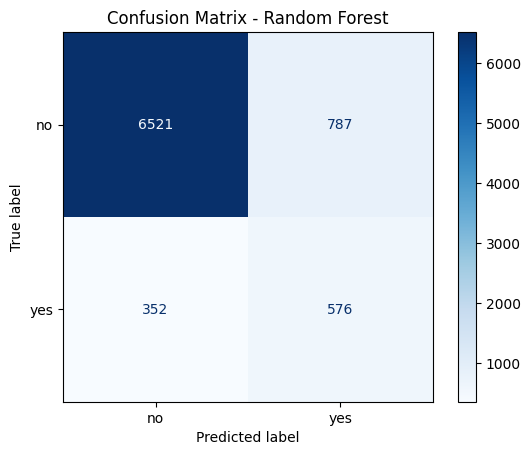

In [55]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train_bal, y_train_bal)
_ = evaluate_model("Random Forest", rf)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Random Forest** builds many decision trees (200 here), each trained on a random part of the data and a random subset of features, and combines their votes. Averaging many trees removes most of the instability of a single tree, and it still captures the non-linear patterns and interactions found during the analysis. The depth was limited to 10 to keep the trees from memorising the training data.

On the test set it reached **Recall 0.62, Precision 0.42, F1 0.50, accuracy 0.86 and ROC-AUC 0.805**. It found **576 of the 928 real subscribers**, wrongly flagged 787 customers and missed 352. Compared with the single Decision Tree it finds more real subscribers (576 against 514) at almost the same precision, and it has the highest F1 and ROC-AUC of the models so far. The tuned Logistic Regression still finds slightly more subscribers (about 65%), but with much lower precision.

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__max_depth': 12, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}
Best CV F1: 0.4822
              precision    recall  f1-score   support

          no       0.95      0.90      0.92      7308
         yes       0.43      0.61      0.51       928

    accuracy                           0.87      8236
   macro avg       0.69      0.76      0.72      8236
weighted avg       0.89      0.87      0.88      8236



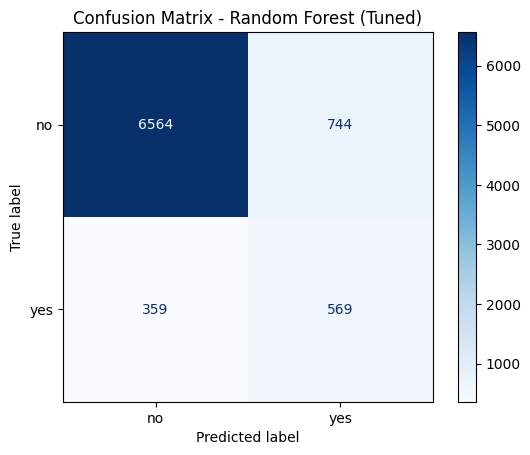

In [56]:
pipe_rf = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [8, 12],
    'clf__min_samples_leaf': [5, 20]
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring='f1', n_jobs=1)
grid_rf.fit(X_train_scaled, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best CV F1:", round(grid_rf.best_score_, 4))

_ = evaluate_model("Random Forest (Tuned)", grid_rf.best_estimator_)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 3-fold stratified cross-validation** was used to search the number of trees (100, 200), the maximum depth (8, 12) and the minimum samples per leaf (5, 20), scored on **F1**. These parameters control how complex each tree is, which is the main source of overfitting in a forest. SMOTE was placed **inside the pipeline**, so synthetic samples are created only from each training fold and the validation fold stays untouched. The best combination was **max_depth = 12, min_samples_leaf = 5 and n_estimators = 200**, with a cross-validated F1 of **0.4822**. All three best values sit at the edge of the grid, so slightly deeper or larger forests might score a little higher, but the gain from tuning was small, so the search was not extended.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Only a marginal one. **Precision rose from 0.423 to 0.433, F1 from 0.503 to 0.508 and accuracy from 0.862 to 0.866**, while **Recall fell slightly (0.621 to 0.613) and ROC-AUC stayed essentially the same (0.805 to 0.804)**. The tuned forest flags fewer wrong customers (744 instead of 787) and finds almost the same number of real subscribers (569 instead of 576). This shows the default forest was already close to its best, and that the limit comes from the data (the large overlap between subscribers and non-subscribers seen in the pairplot) and not from the settings. Both Random Forest versions remain the strongest models so far by F1 and ROC-AUC.

In [57]:
results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").reset_index(drop=True)
print(results_df.round(4).to_string())

                         Model  Accuracy  Precision  Recall      F1  ROC-AUC
0          Logistic Regression    0.7936     0.2872  0.5614  0.3800   0.7468
1  Logistic Regression (Tuned)    0.8181     0.3402  0.6541  0.4476   0.7898
2                Decision Tree    0.8706     0.4408  0.5539  0.4909   0.7645
3        Decision Tree (Tuned)    0.8475     0.3855  0.5948  0.4678   0.7759
4                Random Forest    0.8617     0.4226  0.6207  0.5028   0.8053
5        Random Forest (Tuned)    0.8661     0.4334  0.6131  0.5078   0.8039


### ML Model - 4 : Gradient Boosting

              precision    recall  f1-score   support

          no       0.94      0.90      0.92      7308
         yes       0.42      0.57      0.48       928

    accuracy                           0.86      8236
   macro avg       0.68      0.73      0.70      8236
weighted avg       0.88      0.86      0.87      8236



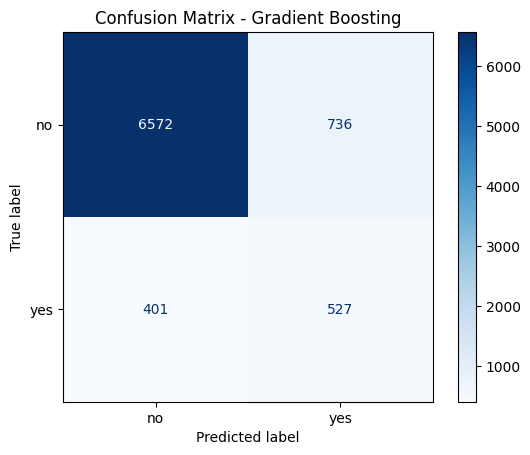

In [58]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train_bal, y_train_bal)
_ = evaluate_model("Gradient Boosting", gb)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Gradient Boosting** builds decision trees one after another, and each new tree is trained to correct the mistakes of the previous ones. This step-by-step correction lets it capture complex non-linear patterns and interactions, and it often performs very well on tabular data like this. The default settings were used first (100 shallow trees of depth 3, learning rate 0.1).

On the test set it reached **Recall 0.57, Precision 0.42, F1 0.48, accuracy 0.86 and ROC-AUC 0.790**. It found **527 of the 928 real subscribers**, wrongly flagged 736 customers and missed 401. Its precision matches the Random Forest, but it finds fewer real subscribers (527 against 576), so its F1 and ROC-AUC are lower (0.48 against 0.50, and 0.790 against 0.805). Tuning may help, because boosting is sensitive to the learning rate and the number of trees.


#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 100}
Best CV F1: 0.4588
              precision    recall  f1-score   support

          no       0.95      0.90      0.92      7308
         yes       0.42      0.59      0.50       928

    accuracy                           0.86      8236
   macro avg       0.69      0.75      0.71      8236
weighted avg       0.89      0.86      0.87      8236



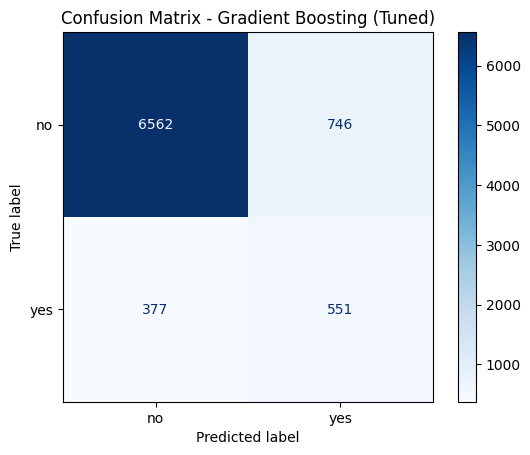

In [59]:
pipe_gb = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', GradientBoostingClassifier(random_state=42))
])

param_grid_gb = {
    'clf__n_estimators': [100, 200],
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_depth': [3, 4]
}

grid_gb = GridSearchCV(pipe_gb, param_grid_gb, cv=cv, scoring='f1', n_jobs=-1)
grid_gb.fit(X_train_scaled, y_train)

print("Best parameters:", grid_gb.best_params_)
print("Best CV F1:", round(grid_gb.best_score_, 4))

_ = evaluate_model("Gradient Boosting (Tuned)", grid_gb.best_estimator_)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 3-fold stratified cross-validation** was used to search the number of trees (100, 200), the learning rate (0.05, 0.1) and the tree depth (3, 4), scored on **F1**. Boosting is sensitive to these three settings: too many deep trees overfit, and a high learning rate makes the model unstable. SMOTE was placed **inside the pipeline**, so synthetic samples are created only from each training fold and the validation fold stays untouched. The best combination was **learning_rate = 0.05, max_depth = 4 and n_estimators = 100**, with a cross-validated F1 of **0.4588**. A slower learning rate with deeper trees won, which means the model benefits from learning in small steps and not from adding more trees.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a small improvement. **Recall rose from 0.568 to 0.594, Precision from 0.417 to 0.425, F1 from 0.481 to 0.495 and accuracy from 0.862 to 0.864**, while **ROC-AUC stayed essentially the same (0.790)**. The tuned model finds 551 of the 928 real subscribers instead of 527, at the cost of 10 more wrongly flagged customers (746 instead of 736). It is still slightly behind the Random Forest (F1 0.508 and ROC-AUC 0.804 for the tuned forest), so boosting gives no advantage on this data.

In [60]:
results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").reset_index(drop=True)
print(results_df.round(4).to_string())

                         Model  Accuracy  Precision  Recall      F1  ROC-AUC
0          Logistic Regression    0.7936     0.2872  0.5614  0.3800   0.7468
1  Logistic Regression (Tuned)    0.8181     0.3402  0.6541  0.4476   0.7898
2                Decision Tree    0.8706     0.4408  0.5539  0.4909   0.7645
3        Decision Tree (Tuned)    0.8475     0.3855  0.5948  0.4678   0.7759
4                Random Forest    0.8617     0.4226  0.6207  0.5028   0.8053
5        Random Forest (Tuned)    0.8661     0.4334  0.6131  0.5078   0.8039
6            Gradient Boosting    0.8619     0.4173  0.5679  0.4811   0.7901
7    Gradient Boosting (Tuned)    0.8636     0.4248  0.5938  0.4953   0.7907


### ML Model - 5 : XGBoost

              precision    recall  f1-score   support

          no       0.93      0.94      0.94      7308
         yes       0.49      0.44      0.46       928

    accuracy                           0.88      8236
   macro avg       0.71      0.69      0.70      8236
weighted avg       0.88      0.88      0.88      8236



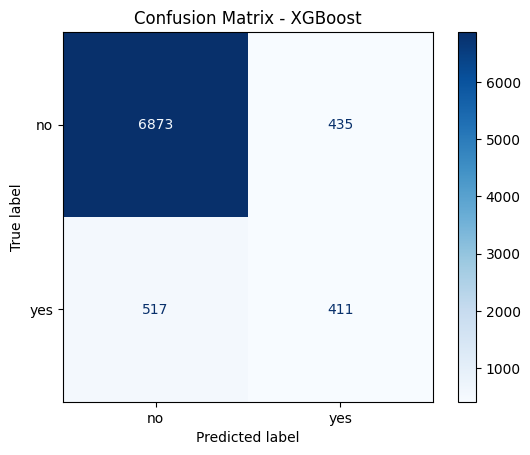

In [61]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4,
                    subsample=0.8, colsample_bytree=0.8,
                    eval_metric="logloss", random_state=42, n_jobs=-1)
xgb.fit(X_train_bal, y_train_bal)
_ = evaluate_model("XGBoost", xgb)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**XGBoost** is an optimised version of gradient boosting. It also builds trees one after another, each correcting the previous ones, but it adds regularisation and row and column sampling (80% each here), which makes it faster and less prone to overfitting. The first run used 200 trees of depth 4 with a learning rate of 0.1.

On the test set it reached **Precision 0.49, Recall 0.44, F1 0.46, accuracy 0.88 and ROC-AUC 0.785**. It found **411 of the 928 real subscribers**, wrongly flagged only 435 customers and missed 517. It is the most cautious model so far: it has the highest precision and accuracy, so a larger share of the customers it flags really subscribe, but it finds fewer real subscribers than the Random Forest (411 against 576), so its F1 is lower (0.46 against 0.50). It would suit a campaign where each call is expensive, and less so where missing a buyer is costly.

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100, 'clf__subsample': 0.8}
Best CV F1: 0.4583
              precision    recall  f1-score   support

          no       0.95      0.88      0.91      7308
         yes       0.40      0.61      0.48       928

    accuracy                           0.85      8236
   macro avg       0.67      0.75      0.70      8236
weighted avg       0.89      0.85      0.87      8236



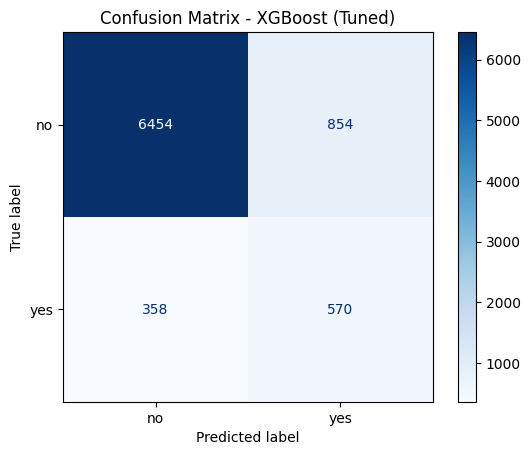

In [62]:
pipe_xgb = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1))
])

param_grid_xgb = {
    'clf__n_estimators': [100, 200],
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_depth': [3, 4],
    'clf__subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(pipe_xgb, param_grid_xgb, cv=cv, scoring='f1', n_jobs=1)
grid_xgb.fit(X_train_scaled, y_train)

print("Best parameters:", grid_xgb.best_params_)
print("Best CV F1:", round(grid_xgb.best_score_, 4))

_ = evaluate_model("XGBoost (Tuned)", grid_xgb.best_estimator_)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 3-fold stratified cross-validation** was used to search the number of trees (100, 200), the learning rate (0.05, 0.1), the tree depth (3, 4) and the row sampling share (0.8, 1.0), scored on **F1**. XGBoost is sensitive to these settings, and the F1 score pushes the search towards finding more real subscribers. SMOTE was placed **inside the pipeline**, so synthetic samples are created only from each training fold and the validation fold stays untouched. The best combination was **learning_rate = 0.05, max_depth = 3, n_estimators = 100 and subsample = 0.8**, with a cross-validated F1 of **0.4583**. The winner is the simplest, slowest-learning model in the grid (it sits at the edge for the learning rate, depth and number of trees), so an even simpler model might score slightly higher.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a moderate one. **Recall rose from 0.44 to 0.61, F1 from 0.463 to 0.485 and ROC-AUC from 0.785 to 0.793**, and the model found 570 real subscribers instead of 411. The cost was lower **Precision (0.49 to 0.40)** and **accuracy (0.88 to 0.85)**, because it now flags many more customers (1,424 instead of 846). Tuning therefore moved XGBoost from a cautious model to a balanced one. It still does not beat the Random Forest (F1 0.508, ROC-AUC 0.804 for the tuned forest).

In [63]:
results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").reset_index(drop=True)
print(results_df.round(4).to_string())

                         Model  Accuracy  Precision  Recall      F1  ROC-AUC
0          Logistic Regression    0.7936     0.2872  0.5614  0.3800   0.7468
1  Logistic Regression (Tuned)    0.8181     0.3402  0.6541  0.4476   0.7898
2                Decision Tree    0.8706     0.4408  0.5539  0.4909   0.7645
3        Decision Tree (Tuned)    0.8475     0.3855  0.5948  0.4678   0.7759
4                Random Forest    0.8617     0.4226  0.6207  0.5028   0.8053
5        Random Forest (Tuned)    0.8661     0.4334  0.6131  0.5078   0.8039
6            Gradient Boosting    0.8619     0.4173  0.5679  0.4811   0.7901
7    Gradient Boosting (Tuned)    0.8636     0.4248  0.5938  0.4953   0.7907
8                      XGBoost    0.8844     0.4858  0.4429  0.4634   0.7852
9              XGBoost (Tuned)    0.8528     0.4003  0.6142  0.4847   0.7934


## Model Comparison Report

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

The target is imbalanced (only 11.3% of customers subscribe), so **accuracy was not used to choose the model**: a model that always predicts "no" is 89% accurate and finds nobody. Four metrics were used instead:
- **Recall** shows how many of the real subscribers the model finds. A missed buyer is lost revenue.
- **Precision** shows how many of the customers the model flags really subscribe. Each wrong flag is a wasted call and an annoyed customer.
- **F1-score** balances the two, so it was the main metric for ranking the models.
- **ROC-AUC** shows how well the model ranks likely subscribers above non-subscribers across all thresholds, so the bank can later choose a call list size that fits its budget.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

                         Model  Accuracy  Precision  Recall      F1  ROC-AUC
0        Random Forest (Tuned)    0.8661     0.4334  0.6131  0.5078   0.8039
1                Random Forest    0.8617     0.4226  0.6207  0.5028   0.8053
2    Gradient Boosting (Tuned)    0.8636     0.4248  0.5938  0.4953   0.7907
3                Decision Tree    0.8706     0.4408  0.5539  0.4909   0.7645
4              XGBoost (Tuned)    0.8528     0.4003  0.6142  0.4847   0.7934
5            Gradient Boosting    0.8619     0.4173  0.5679  0.4811   0.7901
6        Decision Tree (Tuned)    0.8475     0.3855  0.5948  0.4678   0.7759
7                      XGBoost    0.8844     0.4858  0.4429  0.4634   0.7852
8  Logistic Regression (Tuned)    0.8181     0.3402  0.6541  0.4476   0.7898
9          Logistic Regression    0.7936     0.2872  0.5614  0.3800   0.7468


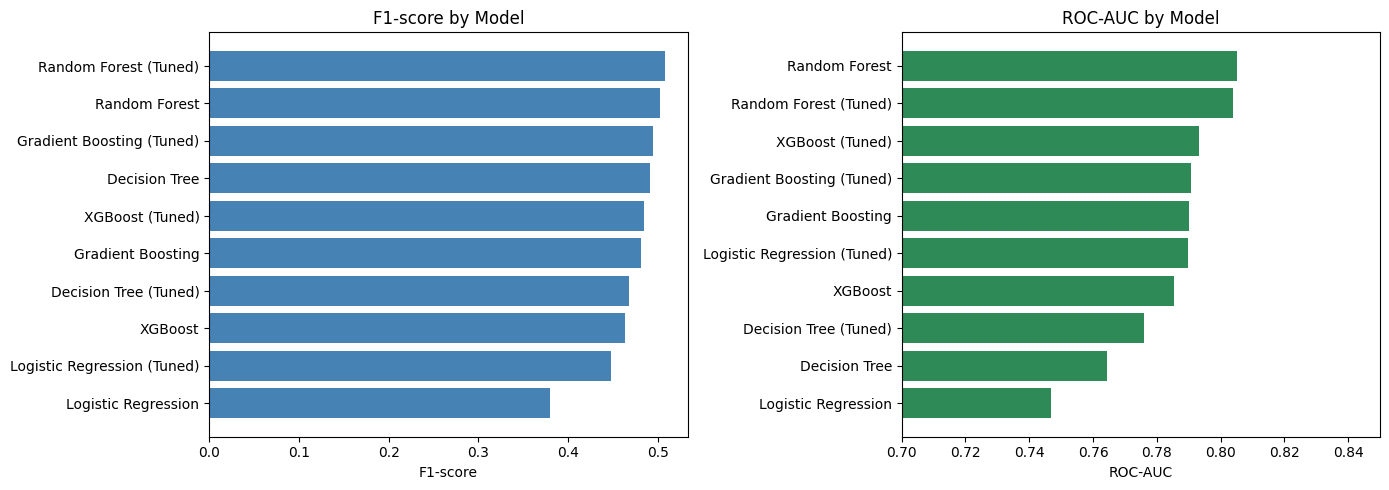

In [64]:
comparison = (pd.DataFrame(results)
                .drop_duplicates(subset="Model", keep="last")
                .sort_values("F1", ascending=False)
                .reset_index(drop=True))
print(comparison.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = comparison.sort_values("F1")
axes[0].barh(order["Model"], order["F1"], color="steelblue")
axes[0].set_title("F1-score by Model")
axes[0].set_xlabel("F1-score")
order = comparison.sort_values("ROC-AUC")
axes[1].barh(order["Model"], order["ROC-AUC"], color="seagreen")
axes[1].set_title("ROC-AUC by Model")
axes[1].set_xlabel("ROC-AUC")
axes[1].set_xlim(0.7, 0.85)
plt.tight_layout()
plt.show()

**Final model: Random Forest (tuned)**

Ten models were compared on the same untouched test set (8,236 customers, 928 real subscribers). The tuned Random Forest was chosen for these reasons:
- **Best balance:** it has the highest F1-score of all models (0.508) and one of the two highest ROC-AUC values (0.804, level with the baseline forest at 0.805).
- **Business value:** it finds **569 of the 928 real subscribers (recall 0.61)** while wrongly flagging 744 customers. About 43% of the customers it flags really subscribe, roughly 3.8 times the 11.3% hit rate of random calling. Calling the 1,313 customers it flags (16% of the list) would reach 61% of all subscribers.
- **Honest validation:** its settings were chosen with stratified cross-validation, with SMOTE inside the pipeline so no synthetic data leaked into validation. The cross-validated F1 (0.482) is close to the test F1 (0.508), so the model is stable and not overfitted.
- **Non-linear patterns:** it captures the interactions found in the analysis (previous outcome, interest rate, month, contact type), which the linear model cannot.

**Why not the others:** the tuned Logistic Regression finds the most subscribers (recall 0.654) but only 34% of its flagged customers subscribe. The baseline XGBoost has the highest precision and accuracy (0.486 and 0.884) but finds only 44% of subscribers. Gradient Boosting and the tuned XGBoost are slightly lower on both F1 and ROC-AUC, and the single Decision Tree is less stable.

**Limits of this comparison:** the top four models are close (F1 between 0.485 and 0.508), and all were compared on one test split with 928 subscribers, so the ranking among them should not be over-interpreted. The ROC-AUC chart axis starts at 0.70, which makes the gaps look larger than they are. If the bank cares more about reach than cost per call, the tuned Logistic Regression, or a lower decision threshold on the forest, is a reasonable alternative.

### 3. Explain the model which you have used and the feature importance using any model explainability tool.

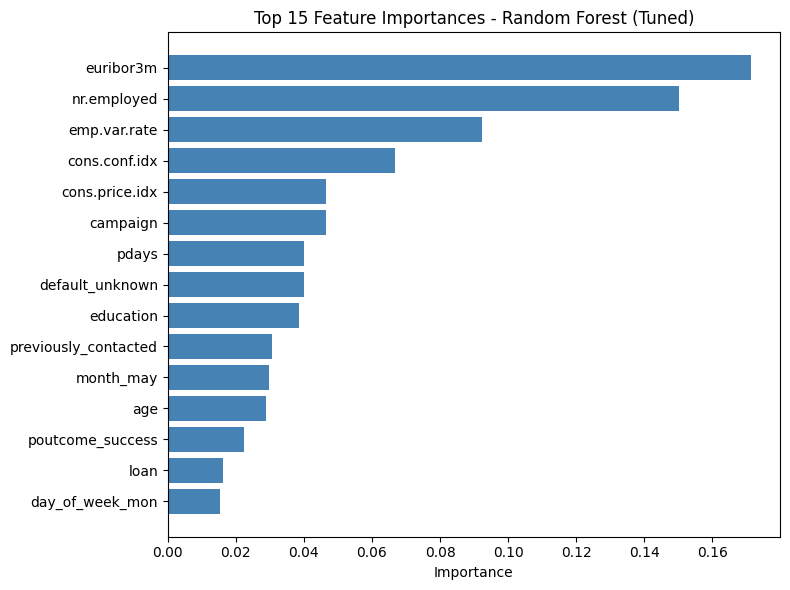

euribor3m               0.1713
nr.employed             0.1503
emp.var.rate            0.0924
cons.conf.idx           0.0669
cons.price.idx          0.0466
campaign                0.0464
pdays                   0.0400
default_unknown         0.0399
education               0.0385
previously_contacted    0.0305


In [66]:
best_rf = grid_rf.best_estimator_.named_steps['clf']
importances = pd.Series(best_rf.feature_importances_, index=X_train_scaled.columns).sort_values(ascending=False)

top15 = importances.head(15).sort_values()
plt.figure(figsize=(8, 6))
plt.barh(top15.index, top15.values, color="steelblue")
plt.title("Top 15 Feature Importances - Random Forest (Tuned)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.head(10).round(4).to_string())

**Model:** the final model is the tuned Random Forest (200 trees, depth 12, at least 5 samples per leaf). Each tree votes "will subscribe" or "will not", and the forest's share of "yes" votes is the predicted probability. **Feature importance** shows how much each feature reduced the trees' prediction error, averaged over all trees. A higher value means the feature was used more often and more effectively to separate subscribers from non-subscribers.

**What the model relies on:**
1. **Economic context dominates.** The five economic indicators (`euribor3m` 0.171, `nr.employed` 0.150, `emp.var.rate` 0.092, `cons.conf.idx` 0.067 and `cons.price.idx` 0.047) together account for about **53%** of the total importance. This agrees with the earlier analysis, where subscribers were contacted when interest rates were low (mean Euribor 2.12 against 3.81) and the Euribor test was strongly significant.
2. **Contact history matters next.** `campaign` (0.046), `pdays` (0.040), `previously_contacted` (0.031) and `poutcome_success` (0.022) describe how often and how recently the customer was contacted.
3. **Customer profile adds a smaller share.** `default_unknown` (0.040), `education` (0.039), `age` (0.029) and `loan` (0.016) matter, but individually less. `month_may` (0.030) captures the weak May results seen in the monthly chart.

**How to read this carefully:**
- Importance shows how much a feature is used, **not whether it raises or lowers** the chance of subscribing. The direction comes from the earlier analysis (low interest rate, a previous success and cellular contact all go with higher subscription).
- The economic indicators are strongly correlated with each other (above 0.9), so the forest splits their credit between them. Each one looks smaller than the group really is, and the ranking among them should not be over-interpreted.
- `poutcome_success` ranks low even though customers with a previous success subscribed at about 65%. It is a rare group (1,373 customers) and overlaps with `pdays` and `previously_contacted`, which carry much of the same information.
- Importance from tree models favours features with many distinct values, so continuous variables can look more important than they really are.


## Future Work
### 4. Save the best performing ML model in a pickle file for deployment

In [67]:
import pickle

artifact = {
    "model": grid_rf.best_estimator_,
    "scaler": scaler,
    "feature_columns": list(X_train_scaled.columns),
    "numeric_columns": num_cols,
}

with open("best_model_random_forest.pkl", "wb") as f:
    pickle.dump(artifact, f)

print("Saved: best_model_random_forest.pkl")

Saved: best_model_random_forest.pkl


In [68]:
from google.colab import files
files.download("best_model_random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5. Load the saved model and make predictions on unseen data (sanity check)

In [69]:
from sklearn.metrics import roc_auc_score

with open("best_model_random_forest.pkl", "rb") as f:
    loaded = pickle.load(f)

cols = loaded["feature_columns"]
sample = X_test_scaled[cols].head(10)

pred_loaded = loaded["model"].predict(sample)
pred_original = grid_rf.best_estimator_.predict(sample)
print("Loaded model gives the same predictions as the original:", (pred_loaded == pred_original).all())

out = pd.DataFrame({
    "probability_yes": loaded["model"].predict_proba(sample)[:, 1].round(3),
    "prediction": pred_loaded,
    "actual": y_test.head(10).values
})
print(out.to_string())

auc = roc_auc_score(y_test, loaded["model"].predict_proba(X_test_scaled[cols])[:, 1])
print("ROC-AUC of the loaded model on the full test set:", round(auc, 4))

Loaded model gives the same predictions as the original: True
   probability_yes  prediction  actual
0            0.112           0       0
1            0.941           1       1
2            0.410           0       0
3            0.442           0       0
4            0.234           0       0
5            0.388           0       0
6            0.465           0       0
7            0.155           0       0
8            0.397           0       0
9            0.334           0       0
ROC-AUC of the loaded model on the full test set: 0.8039


## Suggestions to the Bank Marketing Team

**Result on the test data:** the final model flagged 1,313 customers (16% of the list) and 569 of them really subscribed, which is 61% of all subscribers. Reaching the same 569 subscribers by calling at random (11.3% success) would take about 5,050 calls, so the model-ranked list needs roughly **74% fewer calls** for the same result. This is an estimate from historical data and should be confirmed with a live test.

**1. Call customers in model order.** Score every customer with the saved model and call the highest-probability customers first. The size of the call list can be set to the bank's budget: a short list gives high precision, and a longer list reaches more buyers.

**2. Start with customers who said yes before.** A previous success subscribed at about 65%, against 14% after a failure and 9% with no history. This is the best group to call first, but it is small (1,373 customers), so it cannot carry the campaign alone.

**3. Use mobile numbers.** Cellular contacts subscribed at 14.7% against 5.2% for landlines. Ask for a mobile number whenever customer details are updated. Part of this gap may reflect when each channel was used, so confirm it in the next campaign.

**4. Limit the number of attempts.** Customers who did not subscribe were called up to 56 times, while those who did usually said yes within the first few calls. A limit of 3 to 5 attempts per customer saves cost and avoids annoying customers.

**5. Plan campaign timing around economic conditions.** Subscribers were contacted when the 3-month Euribor rate was low (mean 2.12 against 3.81), and economic indicators make up about 53% of the model's importance. Launch larger campaigns in low-rate periods. The bank cannot control these indicators, so they should guide timing, not customer selection.

**6. Use seasonality carefully.** March, September, October and December show very high rates, but with few calls, so they are indicative only. May has the lowest rate (about 6.5%) and the largest volume. Test more calls in the high-rate months and improve the offer in May instead of dropping it.

**7. Tailor the offer by segment.** Students (about 31%), retired customers (about 25%), single customers (about 14%) and university graduates (about 14%) respond best. Customers in blue-collar and services jobs respond least, but they are a large group, so they need a different message or channel, not exclusion. Housing and personal loans have almost no effect, so these customers should stay on the list.

**8. Improve the data.** The default status is unknown for about 21% of customers, and these customers subscribe far less (about 5% against 13%). Collecting it would help. Keep call duration out of the model, because it is only known after the call.

**9. Test and monitor.** Run a controlled test (model-ranked list against the usual list) in the next campaign, track precision and recall, and retrain the model regularly, because customer behaviour and economic conditions change.

## Conclusion

This project analysed 41,188 phone calls from a Portuguese bank's term deposit campaigns (41,176 after removing 12 duplicates) and built a model to predict which customers will subscribe.

**Data and analysis.** Only 11.3% of customers subscribed. Missing values were hidden as "unknown", `pdays = 999` was a special code, and `duration` was removed because it is only known after the call. Four statistical tests confirmed that contact type, previous outcome and the Euribor rate are strongly related to subscription, while the number of contacts matters less in practice.

**Modelling.** Ten model versions (five algorithms, each untuned and tuned) were compared on an untouched test set. SMOTE was applied to the training data only, and tuning used stratified cross-validation with SMOTE inside the pipeline to avoid leakage. The tuned Random Forest was chosen: F1 0.508, ROC-AUC 0.804, recall 0.613, precision 0.433. It finds 569 of 928 real subscribers, and about 43% of the customers it flags subscribe, against 11.3% for random calling.

**Main drivers.** Economic conditions (about 53% of feature importance), contact history, previous outcome, contact type and customer profile.

**Limitations.** (1) The top models are close, and all were compared on one test split. (2) The data covers 2008 to 2010, including the financial crisis. The economic indicators change over time, so the model may partly learn period effects, and a time-ordered validation would be a stricter test. (3) The results are associations from observational data, not proof of cause. (4) No cost data was available to set the best decision threshold.

**Future work.** Validate on later campaigns in time order, choose the threshold from call cost and deposit value, add model explanations with SHAP, deploy the saved model behind a simple tool for the marketing team, and monitor performance over time.

## Report on Challenges Faced

Each challenge below was met on this data, with the technique used and the reason for it.

| Challenge | Technique used | Why this technique |
|---|---|---|
| Imbalanced target (only 11.3% subscribe) | SMOTE on the training set only, stratified split, and Recall, Precision, F1 and ROC-AUC instead of accuracy | A model that always says "no" is 89% accurate but finds nobody. Balancing only the training data keeps the test result honest. |
| Hidden missing values ("unknown" in 6 columns, 20.9% in default) | Mode for job, marital, education, housing and loan. "unknown" kept as its own category in default | The small shares are safe to fill. Filling a fifth of default would invent data, and "unknown" behaves differently (5% against 13% subscription). |
| Special code pdays = 999 (96.3% of rows) | Binary feature previously_contacted, and 999 replaced with 0 | 999 means "never contacted", not 999 days, and would distort every numeric model. |
| Data leakage from call duration | Column dropped | Duration is only known after the call, so a realistic model cannot use it. |
| Outliers (campaign up to 56, age up to 98) | IQR capping for age and campaign. No capping for previous and pdays | Capping keeps every row and the rare subscribers. For previous and pdays the IQR is zero, so capping would erase the previously contacted customers. |
| Skewed variable (campaign skewness 1.21) | log1p transform (skewness 0.68) | Reduces the long tail and safely handles zeros. |
| Strongly correlated economic indicators (0.91 to 0.97) | Kept all, used regularisation and tree models, checked redundancy with PCA | Dropping them would lose information, and they are the strongest drivers. PCA was used as a diagnostic so the model stays explainable. |
| Leakage from pre-processing and tuning | Split first, scaler fitted on training data only, SMOTE inside the cross-validation pipeline | Prevents test or validation information from reaching training, so the scores are reliable. |
| Several models with very similar scores (top four F1 between 0.485 and 0.508) | Ten model versions compared on the same test set, limits stated openly | The ranking among close models should not be over-interpreted. |
| Best settings sitting at the edge of the grid (Logistic Regression, Random Forest, XGBoost) | Logistic Regression grid extended downwards. Others noted as a limitation | The extra tuning gain was small compared with the cost of a longer search. |
| Technical problems in Colab (slow tuning, lost uploaded file after resets, duplicate result rows when cells were re-run, a table display error) | Small grids, files re-uploaded after resets, duplicates removed from the results table (keep last), interactive table formatter turned off | Kept the work reproducible and the comparison table correct. |## Report on Challenges Faced

Each challenge below was met on this data, with the technique used and the reason for it.

| Challenge | Technique used | Why this technique |
|---|---|---|
| Imbalanced target (only 11.3% subscribe) | SMOTE on the training set only, stratified split, and Recall, Precision, F1 and ROC-AUC instead of accuracy | A model that always says "no" is 89% accurate but finds nobody. Balancing only the training data keeps the test result honest. |
| Hidden missing values ("unknown" in 6 columns, 20.9% in default) | Mode for job, marital, education, housing and loan. "unknown" kept as its own category in default | The small shares are safe to fill. Filling a fifth of default would invent data, and "unknown" behaves differently (5% against 13% subscription). |
| Special code pdays = 999 (96.3% of rows) | Binary feature previously_contacted, and 999 replaced with 0 | 999 means "never contacted", not 999 days, and would distort every numeric model. |
| Data leakage from call duration | Column dropped | Duration is only known after the call, so a realistic model cannot use it. |
| Outliers (campaign up to 56, age up to 98) | IQR capping for age and campaign. No capping for previous and pdays | Capping keeps every row and the rare subscribers. For previous and pdays the IQR is zero, so capping would erase the previously contacted customers. |
| Skewed variable (campaign skewness 1.21) | log1p transform (skewness 0.68) | Reduces the long tail and safely handles zeros. |
| Strongly correlated economic indicators (0.91 to 0.97) | Kept all, used regularisation and tree models, checked redundancy with PCA | Dropping them would lose information, and they are the strongest drivers. PCA was used as a diagnostic so the model stays explainable. |
| Leakage from pre-processing and tuning | Split first, scaler fitted on training data only, SMOTE inside the cross-validation pipeline | Prevents test or validation information from reaching training, so the scores are reliable. |
| Several models with very similar scores (top four F1 between 0.485 and 0.508) | Ten model versions compared on the same test set, limits stated openly | The ranking among close models should not be over-interpreted. |
| Best settings sitting at the edge of the grid (Logistic Regression, Random Forest, XGBoost) | Logistic Regression grid extended downwards. Others noted as a limitation | The extra tuning gain was small compared with the cost of a longer search. |
| Technical problems in Colab (slow tuning, lost uploaded file after resets, duplicate result rows when cells were re-run, a table display error) | Small grids, files re-uploaded after resets, duplicates removed from the results table (keep last), interactive table formatter turned off | Kept the work reproducible and the comparison table correct. |## Report on Challenges Faced

Each challenge below was met on this data, with the technique used and the reason for it.

| Challenge | Technique used | Why this technique |
|---|---|---|
| Imbalanced target (only 11.3% subscribe) | SMOTE on the training set only, stratified split, and Recall, Precision, F1 and ROC-AUC instead of accuracy | A model that always says "no" is 89% accurate but finds nobody. Balancing only the training data keeps the test result honest. |
| Hidden missing values ("unknown" in 6 columns, 20.9% in default) | Mode for job, marital, education, housing and loan. "unknown" kept as its own category in default | The small shares are safe to fill. Filling a fifth of default would invent data, and "unknown" behaves differently (5% against 13% subscription). |
| Special code pdays = 999 (96.3% of rows) | Binary feature previously_contacted, and 999 replaced with 0 | 999 means "never contacted", not 999 days, and would distort every numeric model. |
| Data leakage from call duration | Column dropped | Duration is only known after the call, so a realistic model cannot use it. |
| Outliers (campaign up to 56, age up to 98) | IQR capping for age and campaign. No capping for previous and pdays | Capping keeps every row and the rare subscribers. For previous and pdays the IQR is zero, so capping would erase the previously contacted customers. |
| Skewed variable (campaign skewness 1.21) | log1p transform (skewness 0.68) | Reduces the long tail and safely handles zeros. |
| Strongly correlated economic indicators (0.91 to 0.97) | Kept all, used regularisation and tree models, checked redundancy with PCA | Dropping them would lose information, and they are the strongest drivers. PCA was used as a diagnostic so the model stays explainable. |
| Leakage from pre-processing and tuning | Split first, scaler fitted on training data only, SMOTE inside the cross-validation pipeline | Prevents test or validation information from reaching training, so the scores are reliable. |
| Several models with very similar scores (top four F1 between 0.485 and 0.508) | Ten model versions compared on the same test set, limits stated openly | The ranking among close models should not be over-interpreted. |
| Best settings sitting at the edge of the grid (Logistic Regression, Random Forest, XGBoost) | Logistic Regression grid extended downwards. Others noted as a limitation | The extra tuning gain was small compared with the cost of a longer search. |
| Technical problems in Colab (slow tuning, lost uploaded file after resets, duplicate result rows when cells were re-run, a table display error) | Small grids, files re-uploaded after resets, duplicates removed from the results table (keep last), interactive table formatter turned off | Kept the work reproducible and the comparison table correct. |